<a href="https://colab.research.google.com/github/AsimaZaheer/Conference-Research-Repo/blob/main/version%205.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import zipfile

ZIP_PATH = "/content/drive/MyDrive/WESAD.zip"
EXTRACT_PATH = "/content/WESAD_extracted"

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        f"WESAD.zip nahi mili: {ZIP_PATH}\n"
        "Apni ZIP file ka correct Google Drive path set karo."
    )

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extract ho gaya!")

pkl_files = []

for root, dirs, files in os.walk(EXTRACT_PATH):
    for file in files:
        if file.endswith(".pkl") and file.startswith("S"):
            pkl_files.append(os.path.join(root, file))

print("PKL files found:", len(pkl_files))
print("Example files:", pkl_files[:5])

if not pkl_files:
    raise FileNotFoundError(
        "ZIP ke andar subject PKL files nahi milin. "
        "ZIP structure check karo."
    )

Mounted at /content/drive
Dataset extract ho gaya!
PKL files found: 15
Example files: ['/content/WESAD_extracted/WESAD/S11/S11.pkl', '/content/WESAD_extracted/WESAD/S15/S15.pkl', '/content/WESAD_extracted/WESAD/S5/S5.pkl', '/content/WESAD_extracted/WESAD/S3/S3.pkl', '/content/WESAD_extracted/WESAD/S2/S2.pkl']


In [2]:
import pickle
import numpy as np
import pandas as pd

from scipy.signal import resample_poly
from collections import Counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.ensemble import RandomForestClassifier

In [3]:

from scipy.signal import butter, sosfiltfilt, find_peaks

FS_EDA = 4
FS_BVP = 64
FS_LABEL = 700

WINDOW_SECONDS = 60
STRIDE_SECONDS = 5

WINDOW_SIZE = WINDOW_SECONDS * FS_EDA
STRIDE_SIZE = STRIDE_SECONDS * FS_EDA

BVP_RATIO = FS_BVP // FS_EDA  # 16


# -----------------------------------------
# 1. EDA: statistical + tonic/phasic features
# -----------------------------------------
def extract_eda_features(signal):
    signal = np.asarray(signal, dtype=float).reshape(-1)

    if len(signal) < 20 or not np.all(np.isfinite(signal)):
        raise ValueError("Invalid EDA window")

    # Basic statistical features
    basic = [
        np.mean(signal),
        np.std(signal),
        np.min(signal),
        np.max(signal),
        np.ptp(signal)
    ]

    # Tonic component: slow changes in EDA
    tonic_sos = butter(
        2, 0.05, btype="lowpass",
        fs=FS_EDA, output="sos"
    )
    tonic = sosfiltfilt(tonic_sos, signal)

    # Phasic component: faster changes
    phasic = signal - tonic

    tonic_slope = np.polyfit(
        np.arange(len(tonic)) / FS_EDA,
        tonic, 1
    )[0]

    phasic_peaks, _ = find_peaks(
        phasic,
        distance=FS_EDA,
        prominence=max(np.std(phasic) * 0.5, 1e-8)
    )

    physiological = [
        np.mean(tonic),
        np.std(tonic),
        tonic_slope,
        np.std(phasic),
        np.mean(np.abs(phasic)),
        np.max(phasic),
        len(phasic_peaks) / WINDOW_SECONDS
    ]

    return basic + physiological


# -----------------------------------------
# 2. BVP: pulse-related features at 64 Hz
# -----------------------------------------
def extract_bvp_features(signal):
    signal = np.asarray(signal, dtype=float).reshape(-1)

    if len(signal) < 100 or not np.all(np.isfinite(signal)):
        raise ValueError("Invalid BVP window")

    # Band-pass filter to retain pulse-related frequencies
    bvp_sos = butter(
        3, [0.5, 8.0], btype="bandpass",
        fs=FS_BVP, output="sos"
    )
    filtered = sosfiltfilt(bvp_sos, signal)

    # Detect candidate pulse peaks
    peaks, _ = find_peaks(
        filtered,
        distance=int(0.3 * FS_BVP),
        prominence=max(np.std(filtered) * 0.3, 1e-8)
    )

    # Basic statistics of filtered BVP
    basic = [
        np.mean(filtered),
        np.std(filtered),
        np.min(filtered),
        np.max(filtered),
        np.ptp(filtered)
    ]

    # Pulse intervals and estimated heart rate
    if len(peaks) >= 2:
        intervals = np.diff(peaks) / FS_BVP
        heart_rates = 60.0 / intervals

        # Exclude implausible intervals for these features
        valid = (
            (intervals >= 60.0 / 200.0) &
            (intervals <= 60.0 / 40.0)
        )

        valid_intervals = intervals[valid]
        valid_hr = heart_rates[valid]

        if len(valid_hr) > 0:
            hr_mean = np.mean(valid_hr)
            hr_std = np.std(valid_hr)
            ibi_mean = np.mean(valid_intervals)
            ibi_std = np.std(valid_intervals)
        else:
            hr_mean, hr_std, ibi_mean, ibi_std = [0.0] * 4

        # Peak-to-peak pulse amplitude
        amplitudes = filtered[peaks[1:]] - filtered[peaks[:-1]]

        amp_mean = np.mean(amplitudes)
        amp_std = np.std(amplitudes)

    else:
        hr_mean, hr_std, ibi_mean, ibi_std = [0.0] * 4
        amp_mean, amp_std = 0.0, 0.0

    physiological = [
        hr_mean,
        hr_std,
        ibi_mean,
        ibi_std,
        amp_mean,
        amp_std,
        len(peaks) / WINDOW_SECONDS
    ]

    return basic + physiological


# -----------------------------------------
# 3. Load signals; preserve BVP at 64 Hz
# -----------------------------------------
def load_subject(file_path):
    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    subject_name = os.path.basename(file_path).replace(".pkl", "")
    wrist = data["signal"]["wrist"]

    eda = np.asarray(wrist["EDA"]).reshape(-1)
    bvp_64 = np.asarray(wrist["BVP"]).reshape(-1)
    labels = np.asarray(data["label"]).reshape(-1)

    # Map each 4 Hz EDA sample to the corresponding
    # approximate label sample at 700 Hz
    label_indices = (
        np.arange(len(eda)) * (FS_LABEL / FS_EDA)
    ).astype(int)

    valid = label_indices < len(labels)
    eda = eda[:np.sum(valid)]
    label_indices = label_indices[valid]
    labels_4hz = labels[label_indices]

    # Align duration without downsampling BVP
    n = min(
        len(eda),
        len(labels_4hz),
        len(bvp_64) // BVP_RATIO
    )

    return (
        subject_name,
        eda[:n],
        bvp_64[:n * BVP_RATIO],
        labels_4hz[:n]
    )


# -----------------------------------------
# 4. Windowing and feature extraction
# -----------------------------------------
def make_windows(eda, bvp, labels, subject):
    rows = []

    n = min(len(eda), len(labels), len(bvp) // BVP_RATIO)

    for start in range(
        0, n - WINDOW_SIZE + 1, STRIDE_SIZE
    ):
        end = start + WINDOW_SIZE

        eda_window = eda[start:end]

        # Matching 60-second BVP segment at 64 Hz
        bvp_window = bvp[
            start * BVP_RATIO : end * BVP_RATIO
        ]

        label_window = labels[start:end]

        # Retain only pure Baseline or pure Stress windows
        counts = Counter(label_window.tolist())

        if counts.get(1, 0) == len(label_window):
            target = 0
        elif counts.get(2, 0) == len(label_window):
            target = 1
        else:
            continue

        try:
            eda_features = extract_eda_features(eda_window)
            bvp_features = extract_bvp_features(bvp_window)
        except ValueError:
            continue

        rows.append({
            "subject": subject,
            "label": target,
            "eda_features": eda_features,
            "bvp_features": bvp_features
        })

    return rows


In [4]:
all_rows = []

for file_path in sorted(pkl_files):
    subject = os.path.basename(file_path).replace(".pkl", "")

    # Sirf S2-S17, S12 excluded
    try:
        subject_num = int(subject[1:])
    except (ValueError, IndexError):
        continue

    if subject_num < 2 or subject_num > 17 or subject_num == 12:
        continue

    print("Processing:", subject)

    subject, eda, bvp, labels = load_subject(file_path)

    rows = make_windows(
        eda=eda,
        bvp=bvp,
        labels=labels,
        subject=subject
    )

    all_rows.extend(rows)

    print("  Valid windows:", len(rows))

if not all_rows:
    raise ValueError(
        "Koi valid window nahi bani. Dataset paths, labels aur "
        "signal lengths check karo."
    )

print("\nTotal valid windows:", len(all_rows))
print("Subjects:", sorted(set(r["subject"] for r in all_rows)))

print("\nClass distribution:")
print(pd.Series([r["label"] for r in all_rows])
      .map({0: "Baseline", 1: "Stress"})
      .value_counts())

Processing: S10
  Valid windows: 357
Processing: S11
  Valid windows: 348
Processing: S13
  Valid windows: 345
Processing: S14
  Valid windows: 347
Processing: S15
  Valid windows: 349
Processing: S16
  Valid windows: 347
Processing: S17
  Valid windows: 357
Processing: S2
  Valid windows: 328
Processing: S3
  Valid windows: 332
Processing: S4
  Valid windows: 334
Processing: S5
  Valid windows: 345
Processing: S6
  Valid windows: 342
Processing: S7
  Valid windows: 341
Processing: S8
  Valid windows: 344
Processing: S9
  Valid windows: 341

Total valid windows: 5157
Subjects: ['S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9']

Class distribution:
Baseline    3342
Stress      1815
Name: count, dtype: int64


In [5]:

X_eda = np.array([
    r["eda_features"] for r in all_rows
], dtype=float)

X_fusion = np.array([
    r["eda_features"] + r["bvp_features"]
    for r in all_rows
], dtype=float)

y = np.array([r["label"] for r in all_rows])
groups = np.array([r["subject"] for r in all_rows])

print("EDA feature matrix:", X_eda.shape)
print("EDA+BVP feature matrix:", X_fusion.shape)
print("Labels:", y.shape)

# Same LOSO folds for all three models

logo = LeaveOneGroupOut()
results = []

for fold, (train_idx, test_idx) in enumerate(
    logo.split(X_eda, y, groups), start=1
):
    X_train, X_test = X_eda[train_idx], X_eda[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    test_subject = groups[test_idx][0]

    # 1. Majority-class baseline
    majority_model = DummyClassifier(strategy="most_frequent")
    majority_model.fit(X_train, y_train)
    pred_majority = majority_model.predict(X_test)

    # 2. Logistic Regression
    logistic_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )
    logistic_model.fit(X_train, y_train)
    pred_logistic = logistic_model.predict(X_test)


    # 3. Tuned Random Forest
    train_groups = groups[train_idx]
    n_train_subjects = len(np.unique(train_groups))

    if n_train_subjects < 3:
        raise ValueError(
            "GroupKFold ke liye kam az kam 3 training subjects chahiye."
        )

    inner_cv = GroupKFold(n_splits=3)

    param_grid = {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_leaf": [1, 3],
        "max_features": ["sqrt"]
    }

    search = GridSearchCV(
        estimator=RandomForestClassifier(
            random_state=42,
            class_weight="balanced",
            n_jobs=1
        ),
        param_grid=param_grid,
        scoring="balanced_accuracy",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    search.fit(
        X_train,
        y_train,
        groups=train_groups
    )

    rf_model = search.best_estimator_
    pred_rf = rf_model.predict(X_test)

    print(
        f"{test_subject} best parameters: {search.best_params_}"
    )

    # Evaluate all models on the same held-out subject
    for model_name, predictions in [
        ("Majority Baseline", pred_majority),
        ("Logistic Regression", pred_logistic),
        ("Random Forest", pred_rf)
    ]:
        results.append({
            "Subject": test_subject,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                y_test, predictions
            ),
            "Macro F1": f1_score(
                y_test, predictions,
                average="macro",
                zero_division=0
            )
        })

results_df = pd.DataFrame(results)

# Results for every held-out subject
display(
    results_df.sort_values(["Subject", "Model"])
    .round(4)
)

# Mean and standard deviation across LOSO folds
summary_df = (
    results_df.groupby("Model")[
        ["Accuracy", "Balanced Accuracy", "Macro F1"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("\nLOSO SUMMARY (mean ± standard deviation):")
display(summary_df)


EDA feature matrix: (5157, 12)
EDA+BVP feature matrix: (5157, 24)
Labels: (5157,)
S10 best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
S11 best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 100}
S13 best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 100}
S14 best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
S15 best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 200}
S16 best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
S17 best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 100}
S2 best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 200}
S3 best parameters: {'max_depth': None, 'max_features': 'sqrt

,Subject,Model,Accuracy,Balanced Accuracy,Macro F1
1,S10,Logistic Regression,0.8039,0.7475,0.7639
0,S10,Majority Baseline,0.6275,0.5000,0.3855
2,S10,Random Forest,0.8571,0.8113,0.8320
4,S11,Logistic Regression,0.8534,0.8862,0.8505
3,S11,Majority Baseline,0.6437,0.5000,0.3916
5,S11,Random Forest,0.5862,0.6732,0.5812
7,S13,Logistic Regression,0.6435,0.7216,0.6427
6,S13,Majority Baseline,0.6493,0.5000,0.3937
8,S13,Random Forest,0.7362,0.7969,0.7359
10,S14,Logistic Regression,0.6686,0.5417,0.4882



LOSO SUMMARY (mean ± standard deviation):


Accuracy         Balanced Accuracy         Macro F1  \
                        mean     std              mean     std     mean   
Model                                                                     
Logistic Regression   0.7918  0.1344            0.7807  0.1475   0.7567   
Majority Baseline     0.6482  0.0109            0.5000  0.0000   0.3933   
Random Forest         0.8142  0.1195            0.7967  0.1176   0.7852   

                             
                        std  
Model                        
Logistic Regression  0.1680  
Majority Baseline    0.0040  
Random Forest        0.1537

Drive already mounted at /content/Mydrive; to attempt to forcibly remount, call drive.mount("/content/Mydrive", force_remount=True).
Files in Google Drive:
['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']
Dataset extraction completed successfully!
Processing: S11
Valid windows: 348
Processing: S15
Valid windows: 349
Processing: S5
Valid windows: 345
Processing: S3
Valid windows: 332
Processing: S2
Valid windows: 328
Processing: S17
Valid windows: 357
Processing: S9
Valid windows: 341
Processing: S4
Valid windows: 334
Processing: S8
Valid windows: 344
Processing: S10
Valid windows: 357
Processing: S16
Valid windows: 347
Processing: S7
Valid windows: 341
Processing: S14
Valid windows: 347
Processing: S6
Valid windows: 342
Processing: S13
Valid windows: 345

Total windows: 5157
Subjects: ['S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9']

EDA matrix: (5157, 12)
BVP matrix: (5157, 12)
Fusion matrix: (5157, 24)

Class distributi

,Experiment,Subject,Model,Accuracy,Balanced Accuracy,Macro F1
46,BVP,S10,Logistic Regression,0.3894,0.5134,0.3009
45,BVP,S10,Majority Baseline,0.6275,0.5000,0.3855
47,BVP,S10,Random Forest,0.5266,0.6151,0.5088
49,BVP,S11,Logistic Regression,1.0000,1.0000,1.0000
48,BVP,S11,Majority Baseline,0.6437,0.5000,0.3916
...,...,...,...,...,...,...
129,EDA+BVP Fusion,S8,Majority Baseline,0.6453,0.5000,0.3922
131,EDA+BVP Fusion,S8,Random Forest,0.8692,0.8156,0.8409
133,EDA+BVP Fusion,S9,Logistic Regression,0.8065,0.7282,0.7491
132,EDA+BVP Fusion,S9,Majority Baseline,0.6569,0.5000,0.3965



OVERALL RESULTS


Accuracy         Balanced Accuracy          \
                                       mean     std              mean     std   
Experiment     Model                                                            
BVP            Logistic Regression   0.8262  0.1808            0.8302  0.1675   
               Majority Baseline     0.6482  0.0109            0.5000  0.0000   
               Random Forest         0.8147  0.1270            0.7991  0.1341   
EDA            Logistic Regression   0.7918  0.1344            0.7807  0.1475   
               Majority Baseline     0.6482  0.0109            0.5000  0.0000   
               Random Forest         0.8121  0.1111            0.7908  0.1115   
EDA+BVP Fusion Logistic Regression   0.8475  0.1714            0.8512  0.1487   
               Majority Baseline     0.6482  0.0109            0.5000  0.0000   
               Random Forest         0.8071  0.1631            0.7945  0.1605   

                                   Macro F1          
                                       mean     std  
Experiment     Model                                 
BVP            Logistic Regression   0.8078  0.2021  
               Majority Baseline     0.3933  0.0040  
               Random Forest         0.7894  0.1430  
EDA            Logistic Regression   0.7567  0.1680  
               Majority Baseline     0.3933  0.0040  
               Random Forest         0.7811  0.1464  
EDA+BVP Fusion Logistic Regression   0.8301  0.1912  
               Majority Baseline     0.3933  0.0040  
               Random Forest         0.7679  0.2042

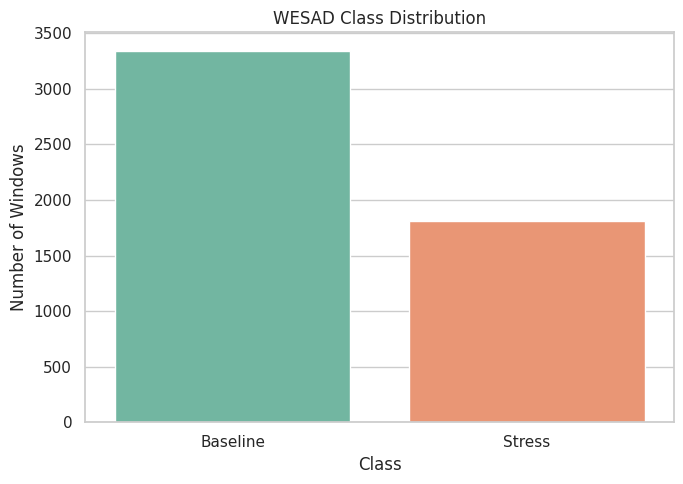

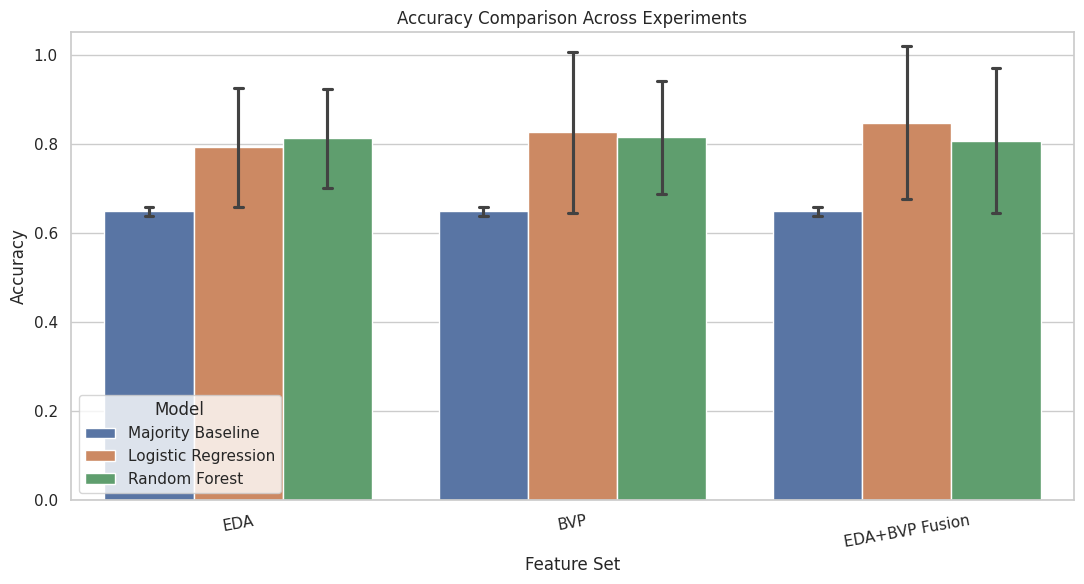

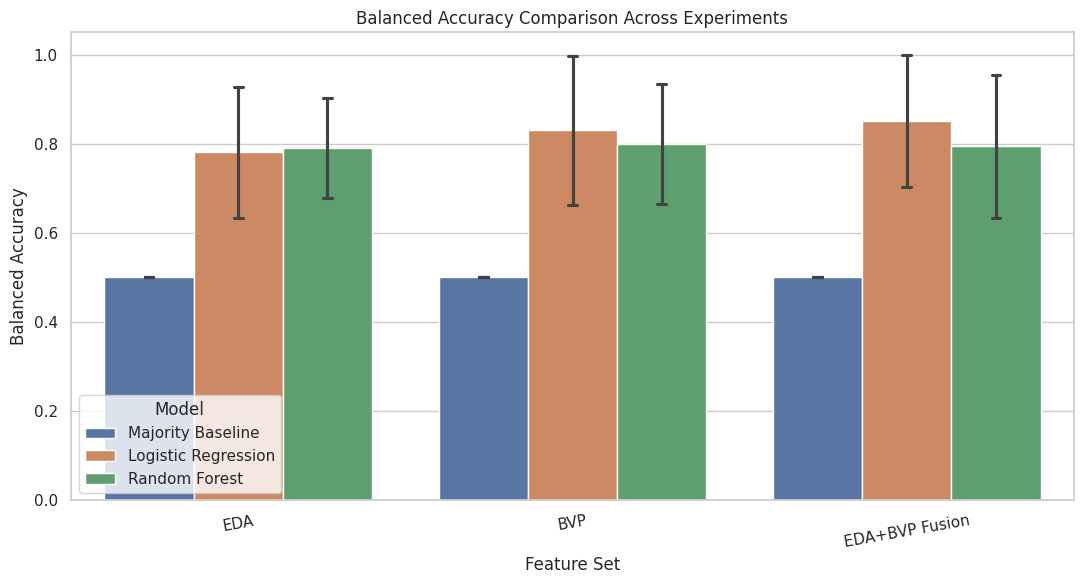

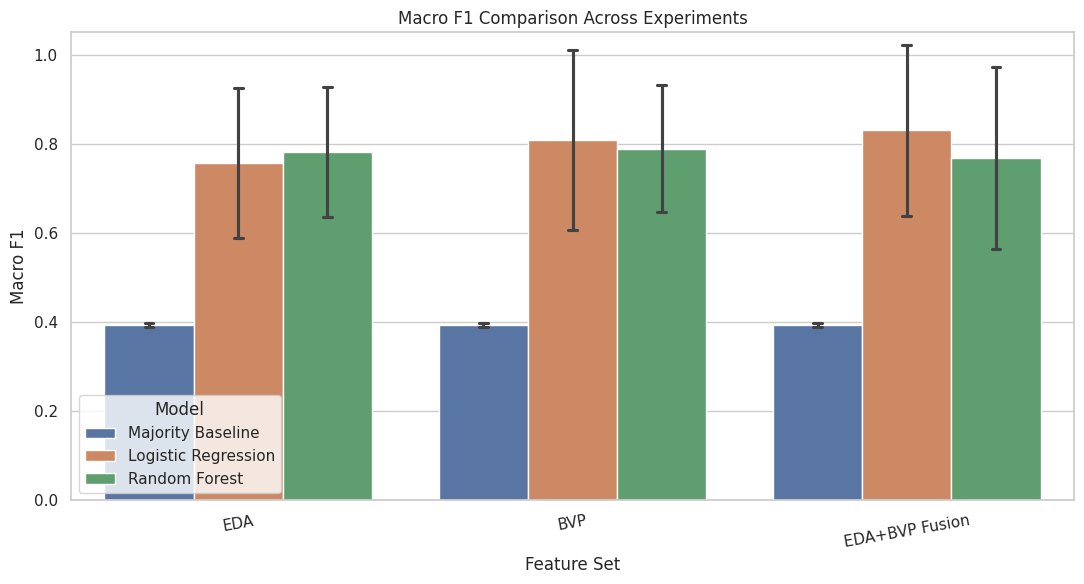

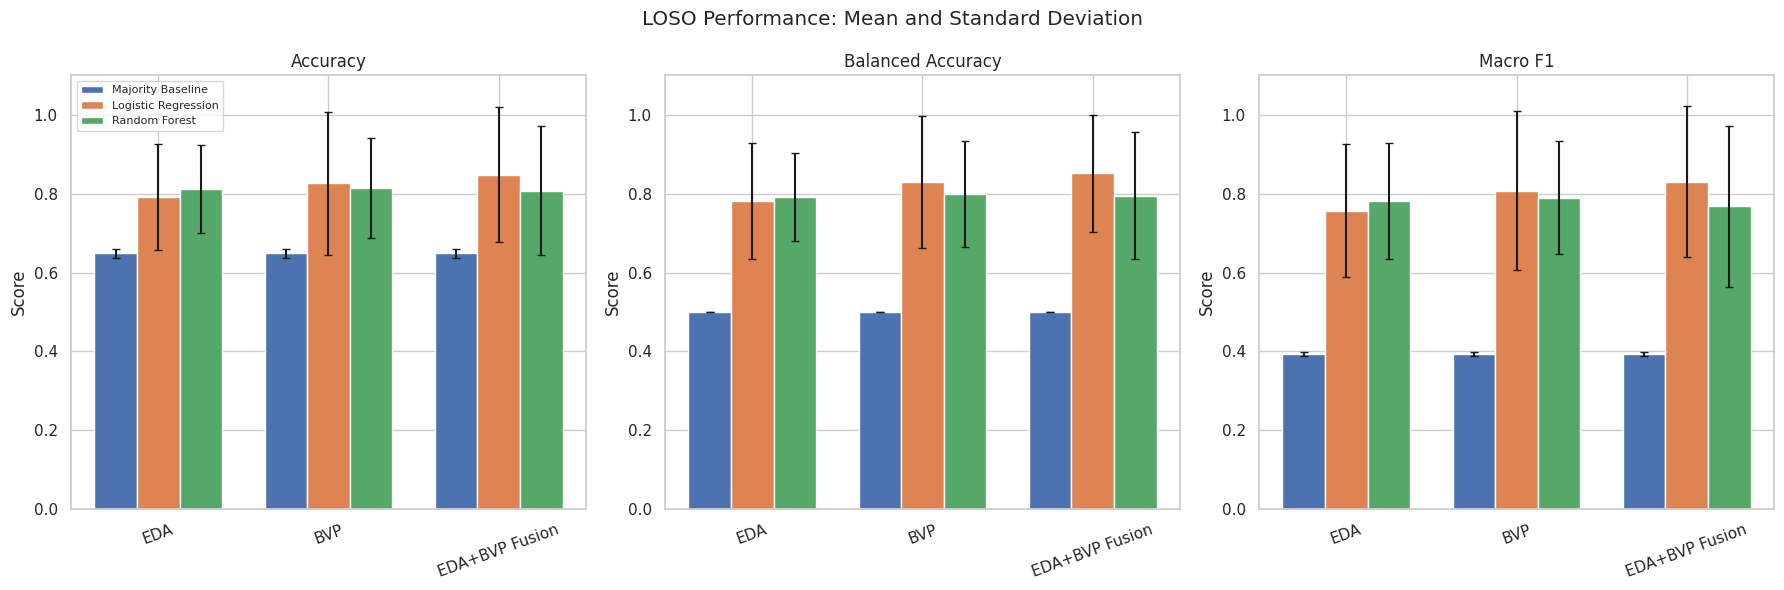

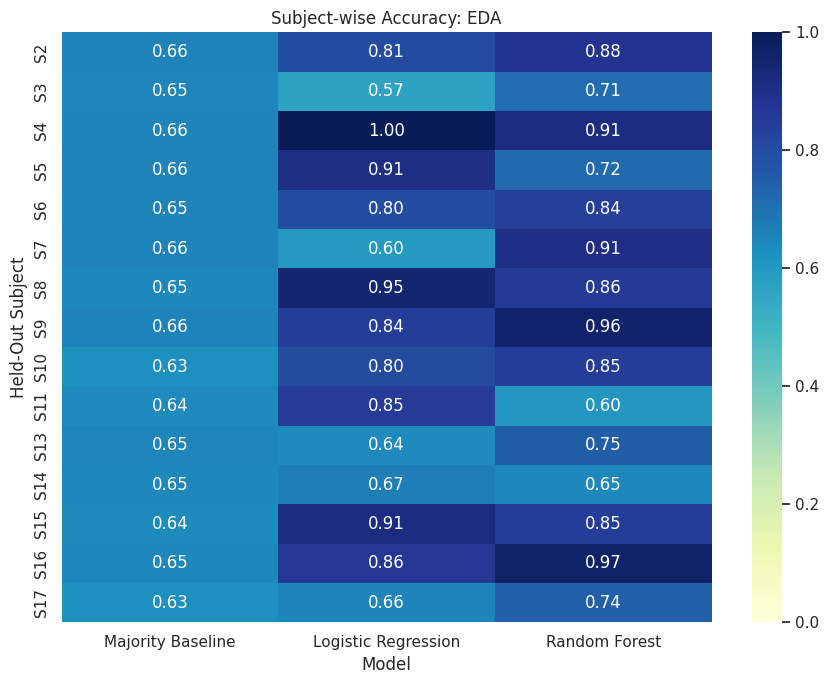

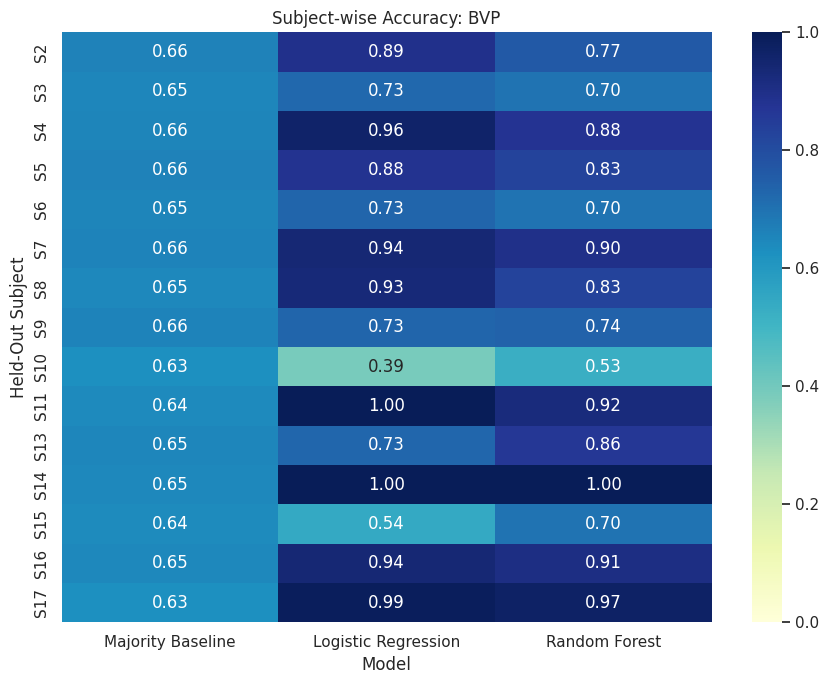

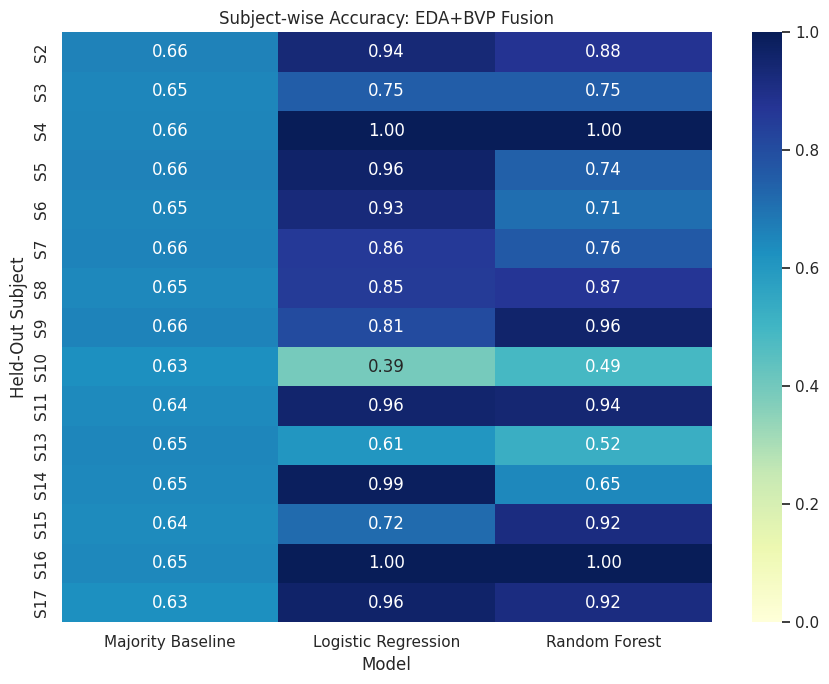

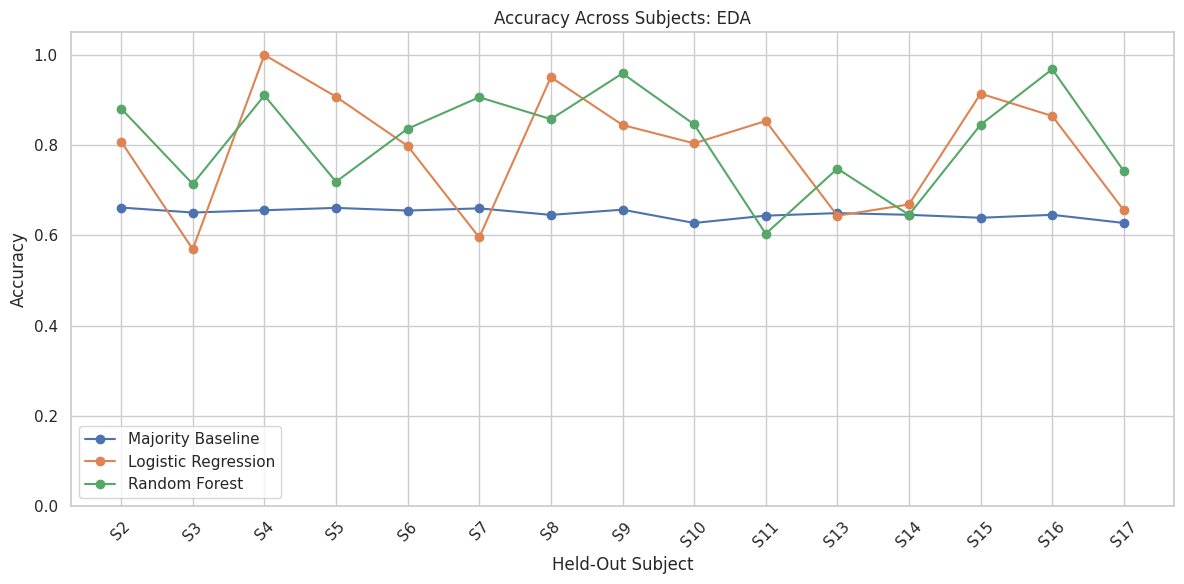

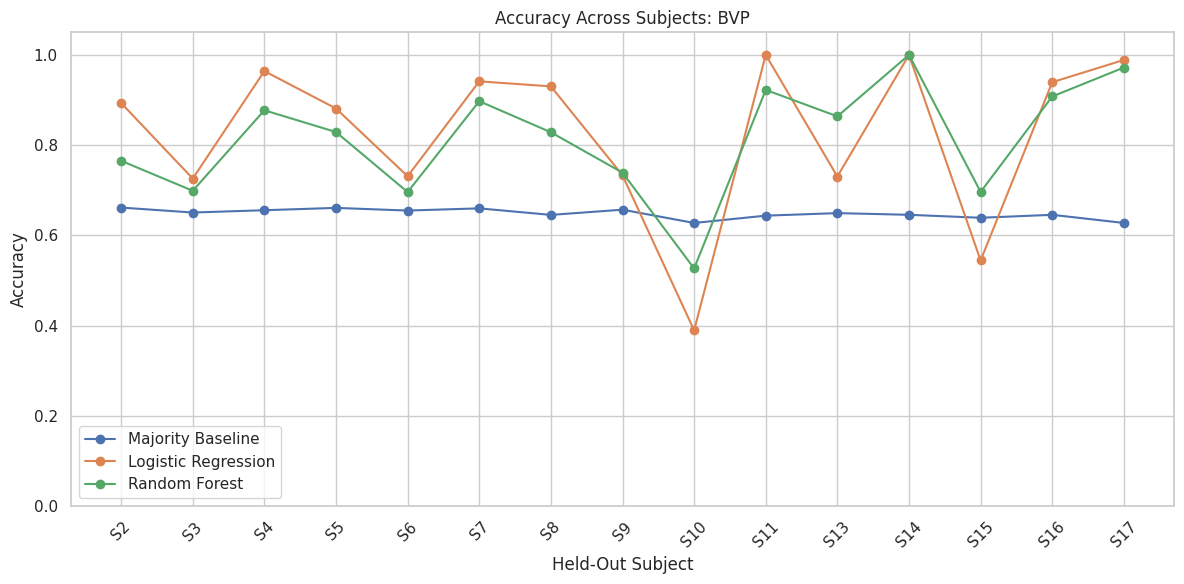

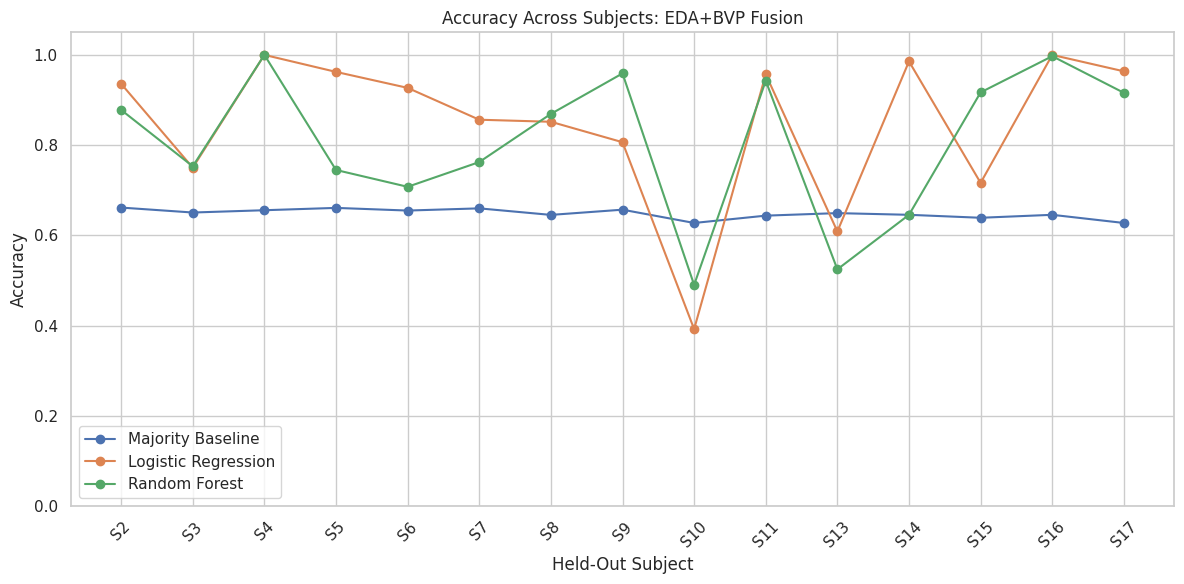

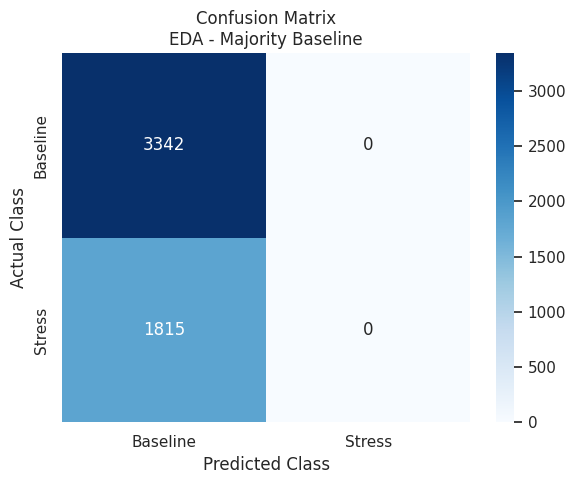

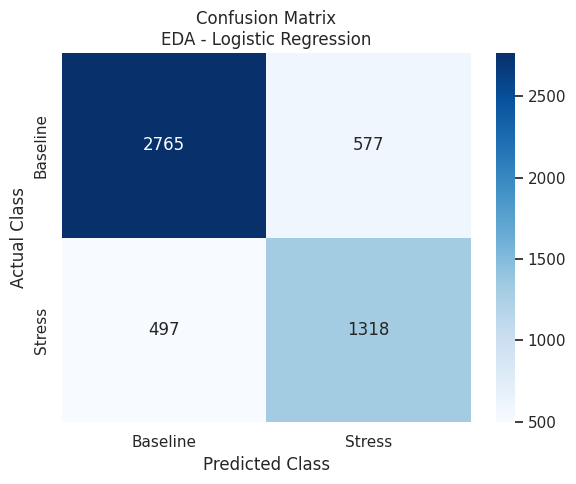

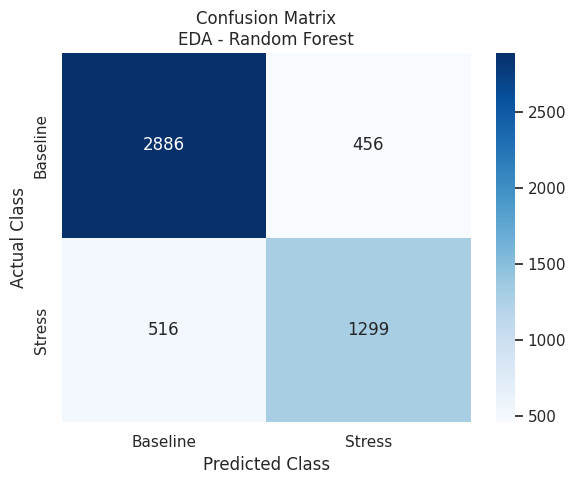

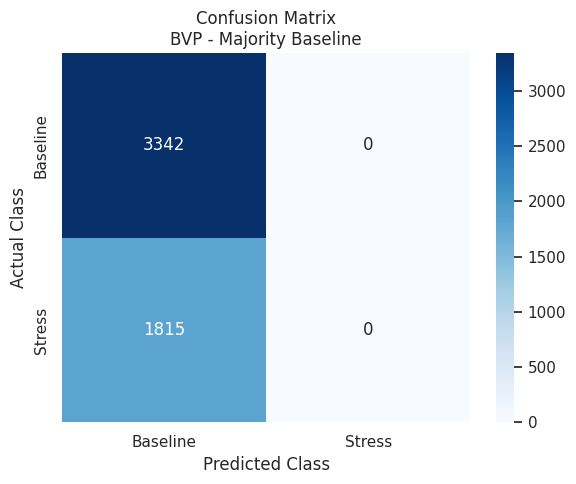

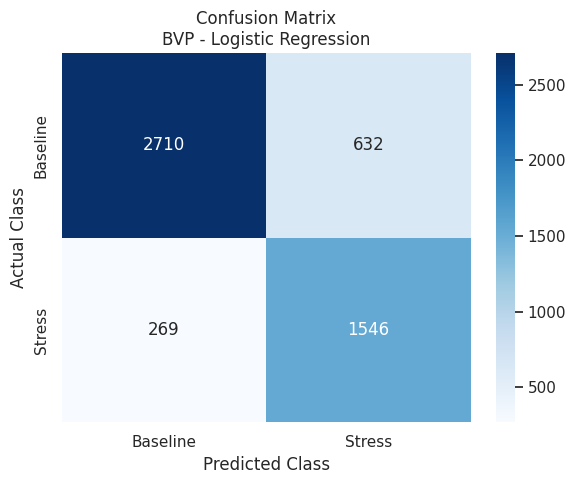

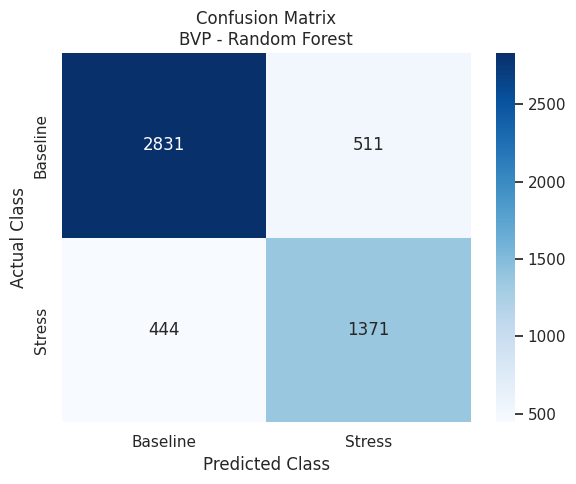

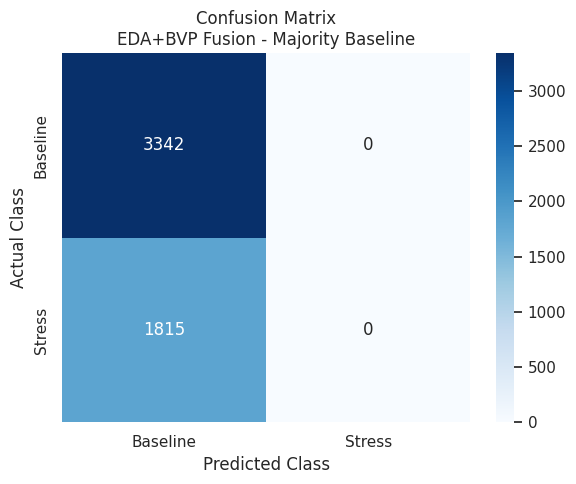

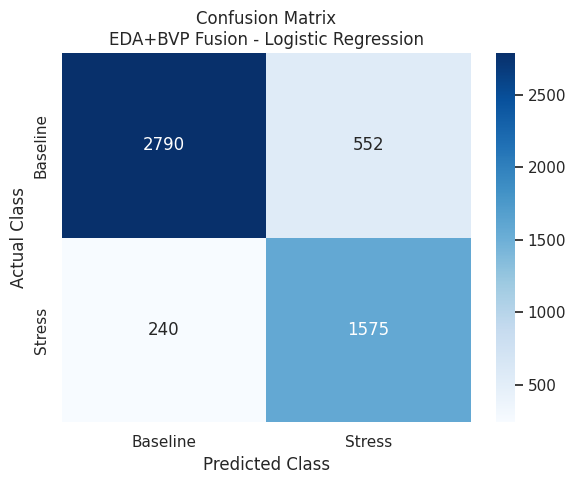

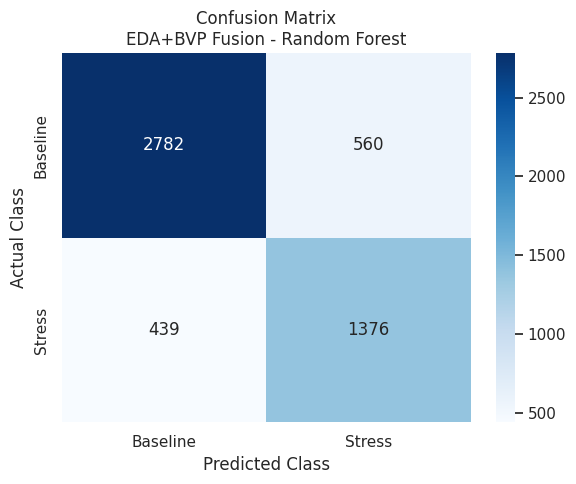

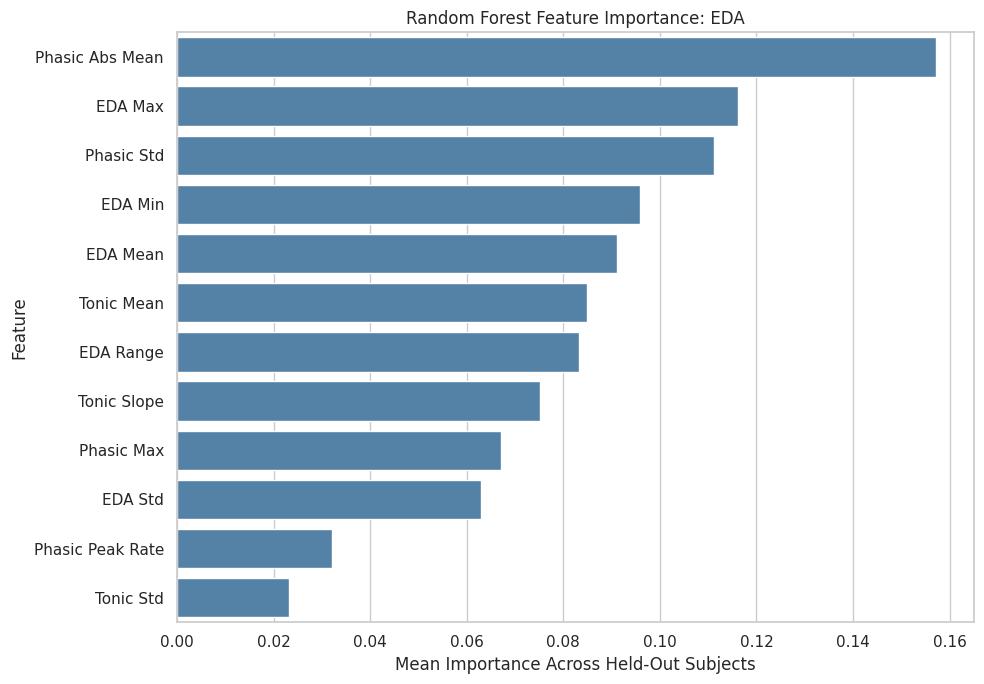

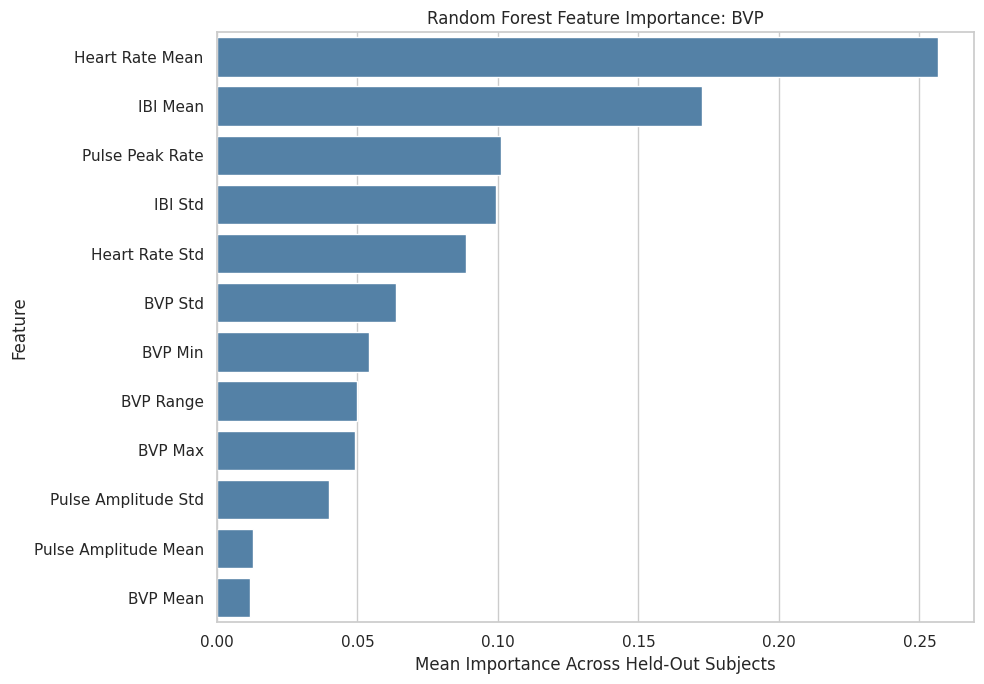

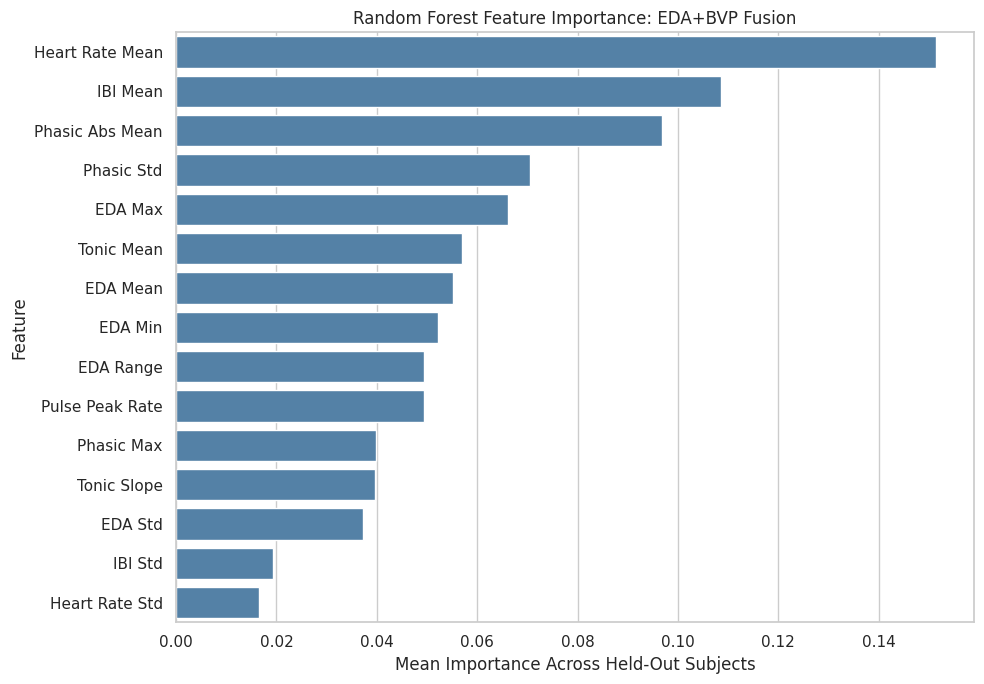

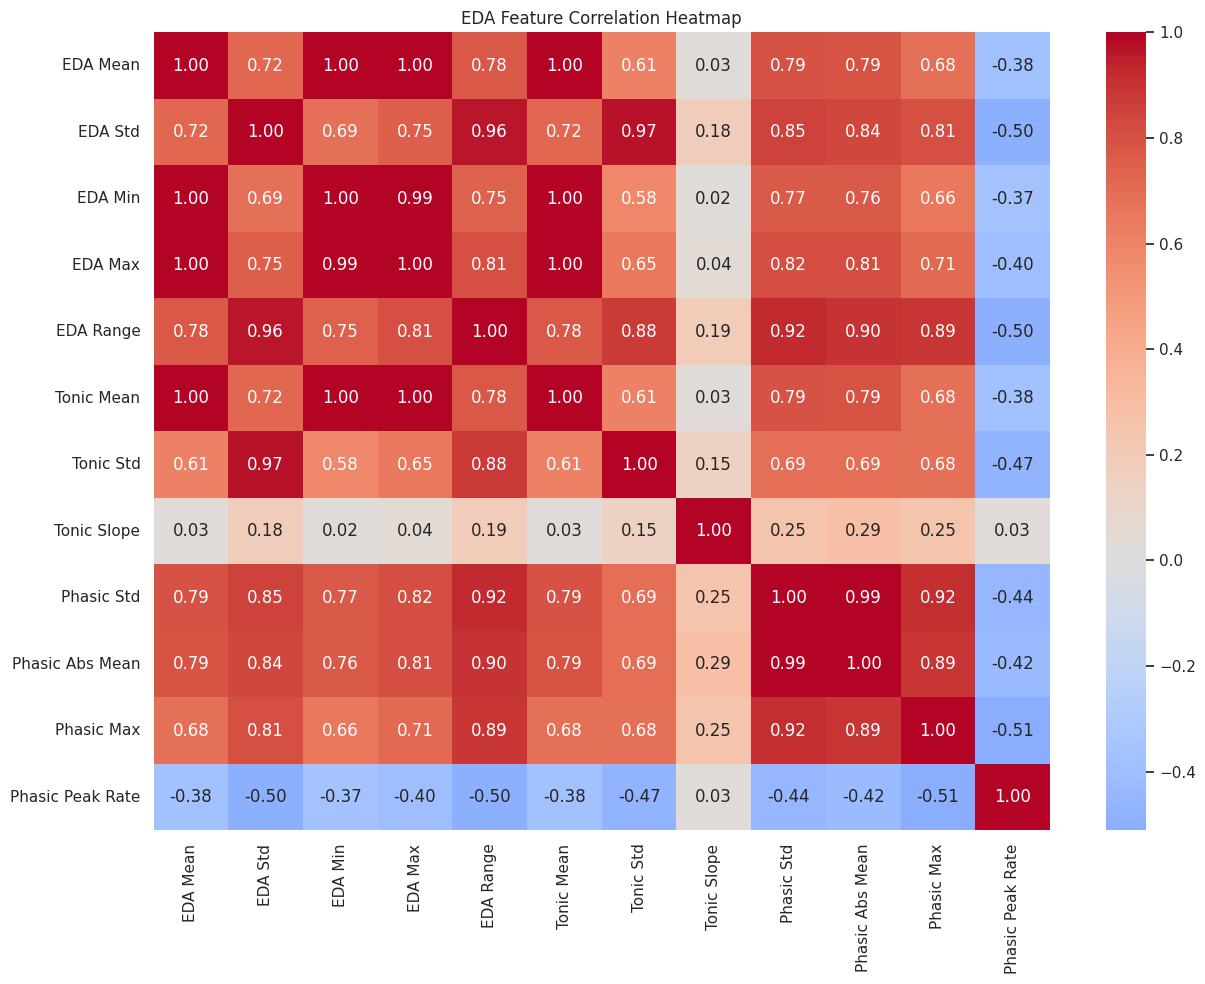

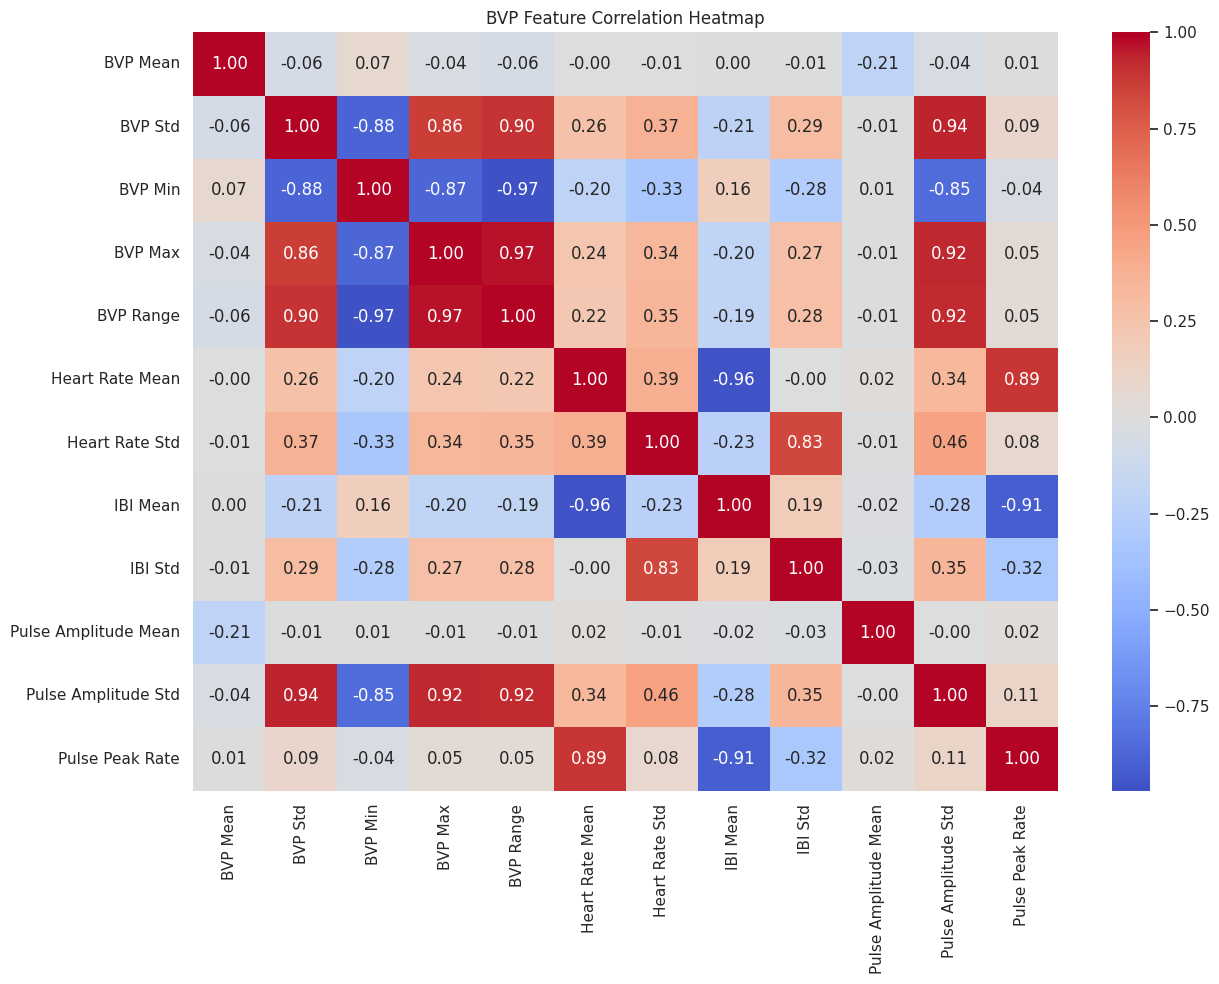

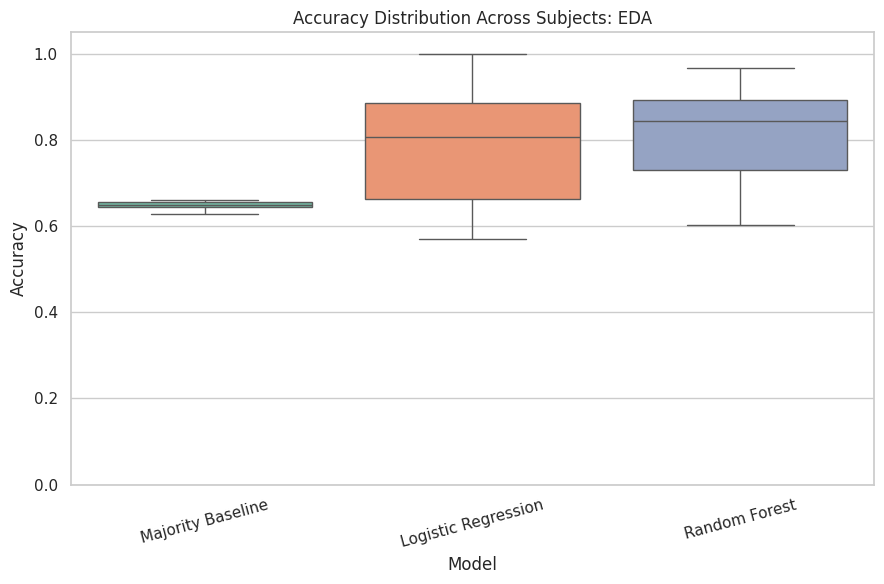

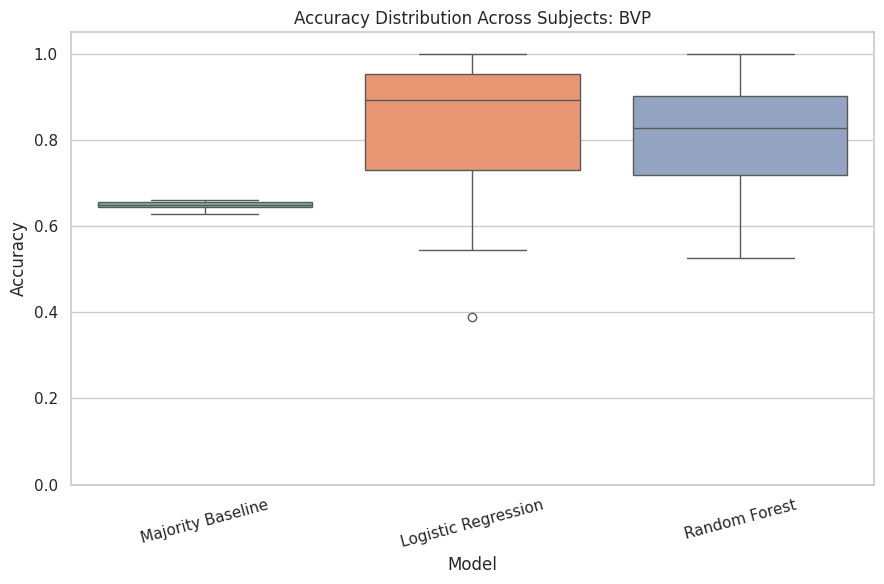

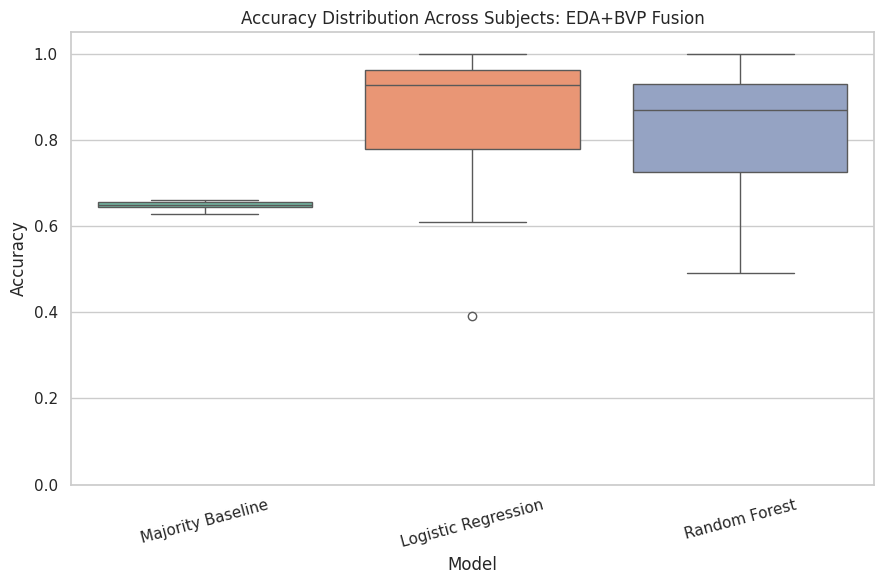

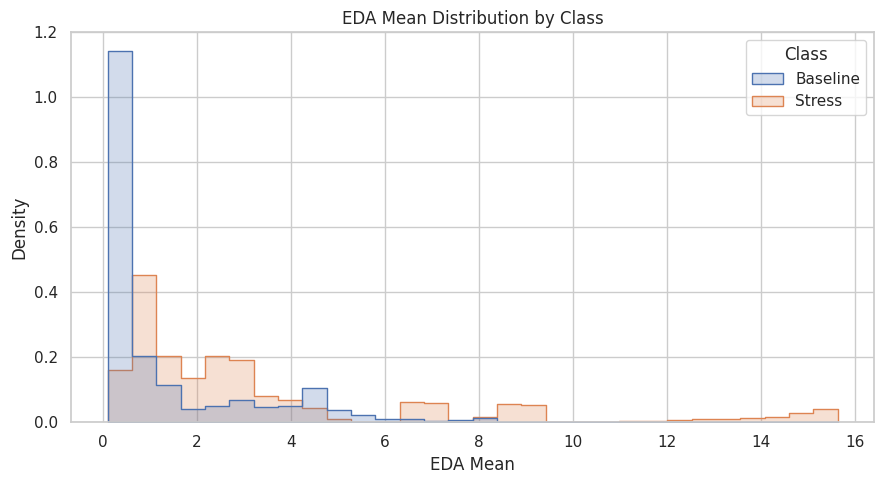

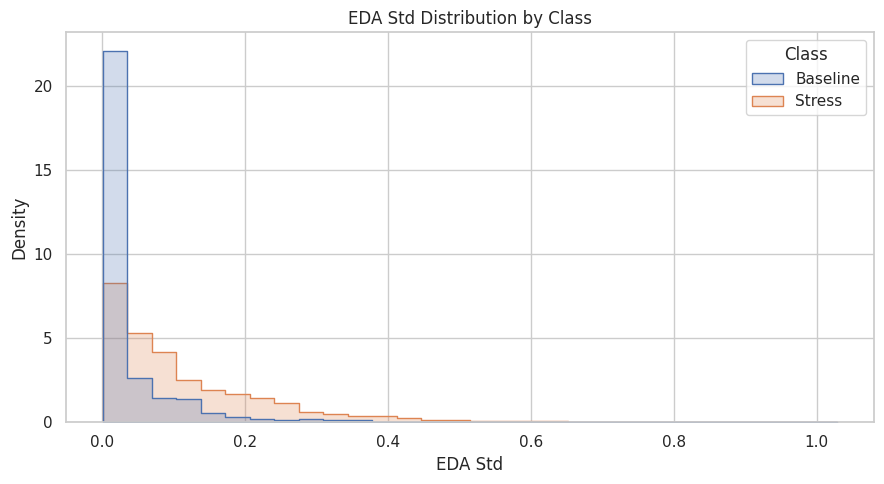

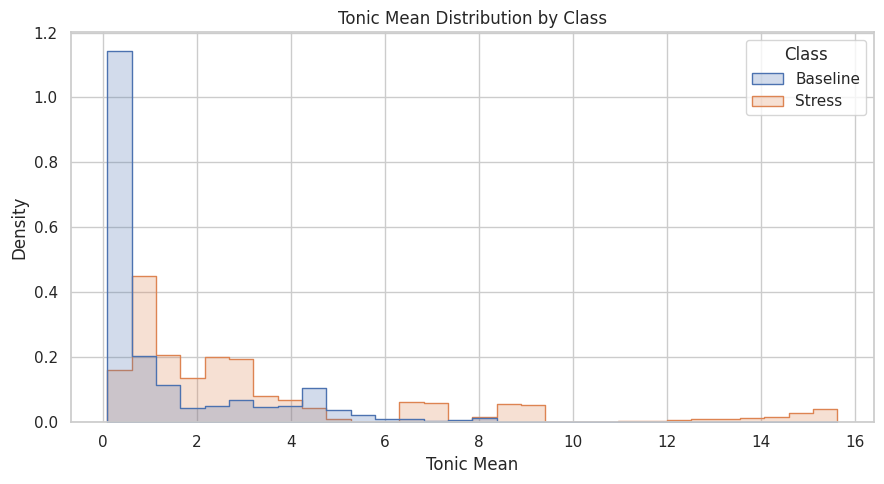

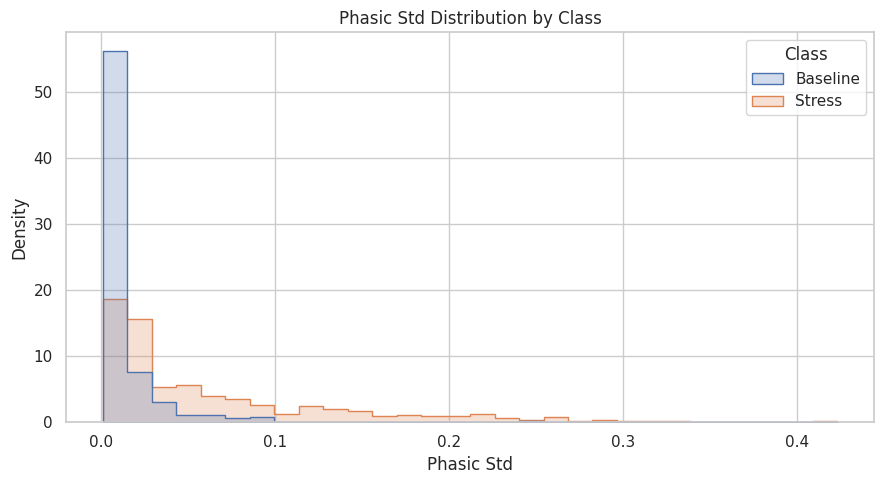

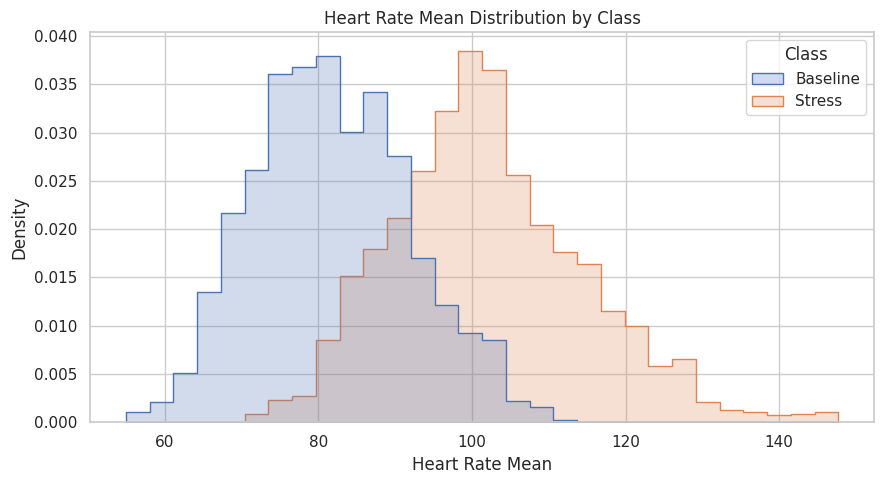

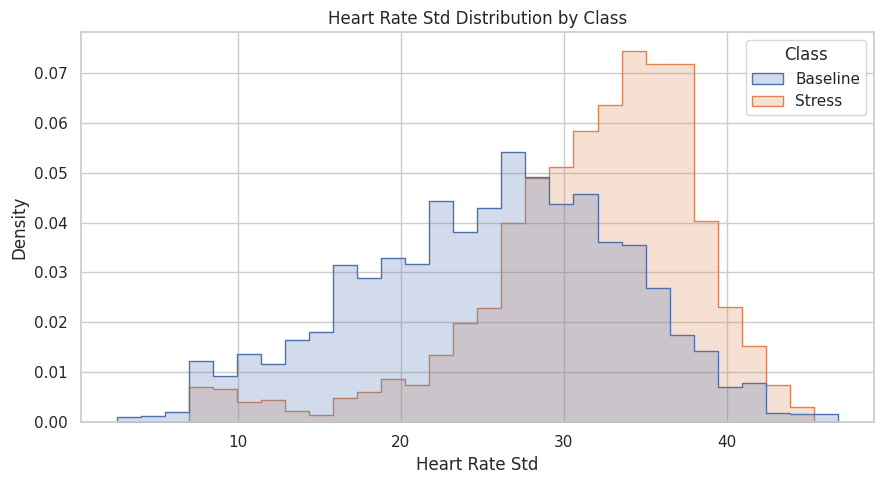

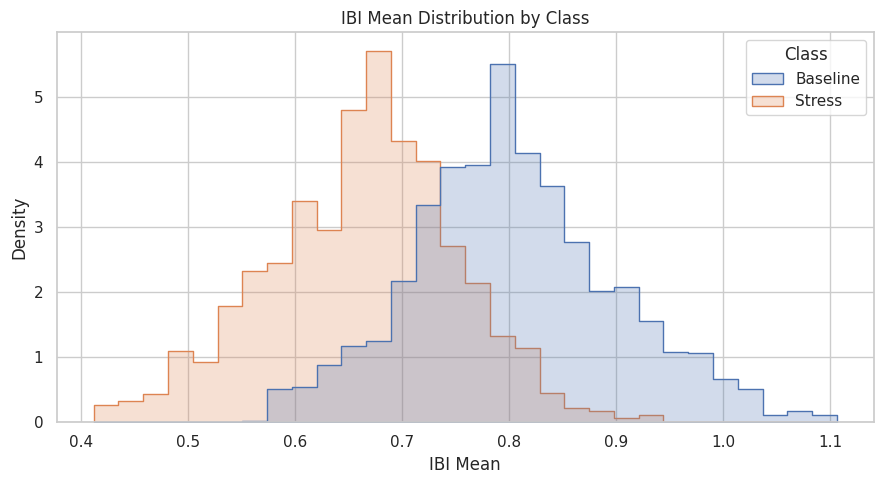

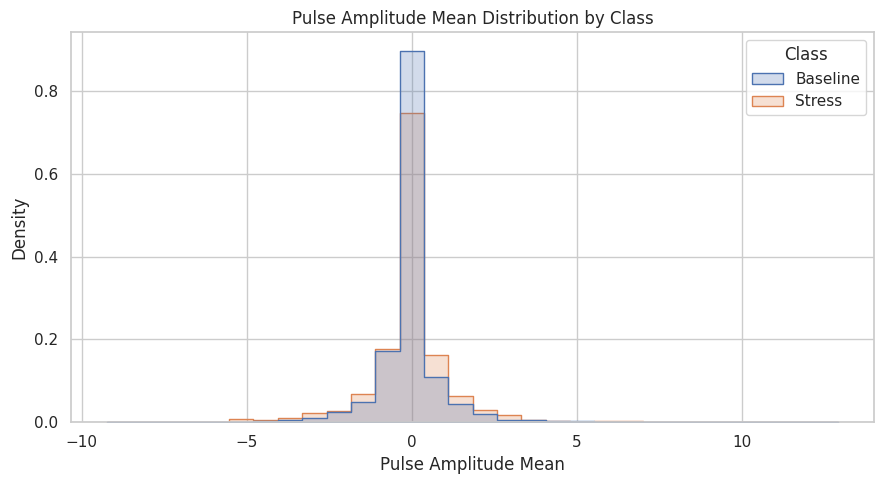

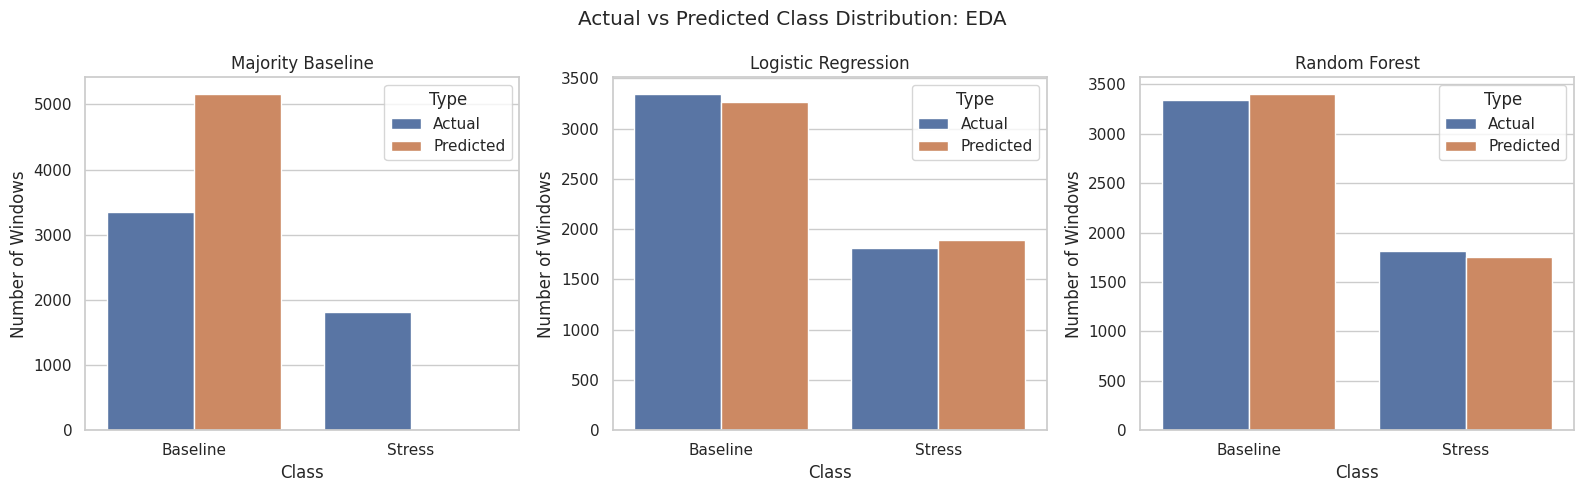

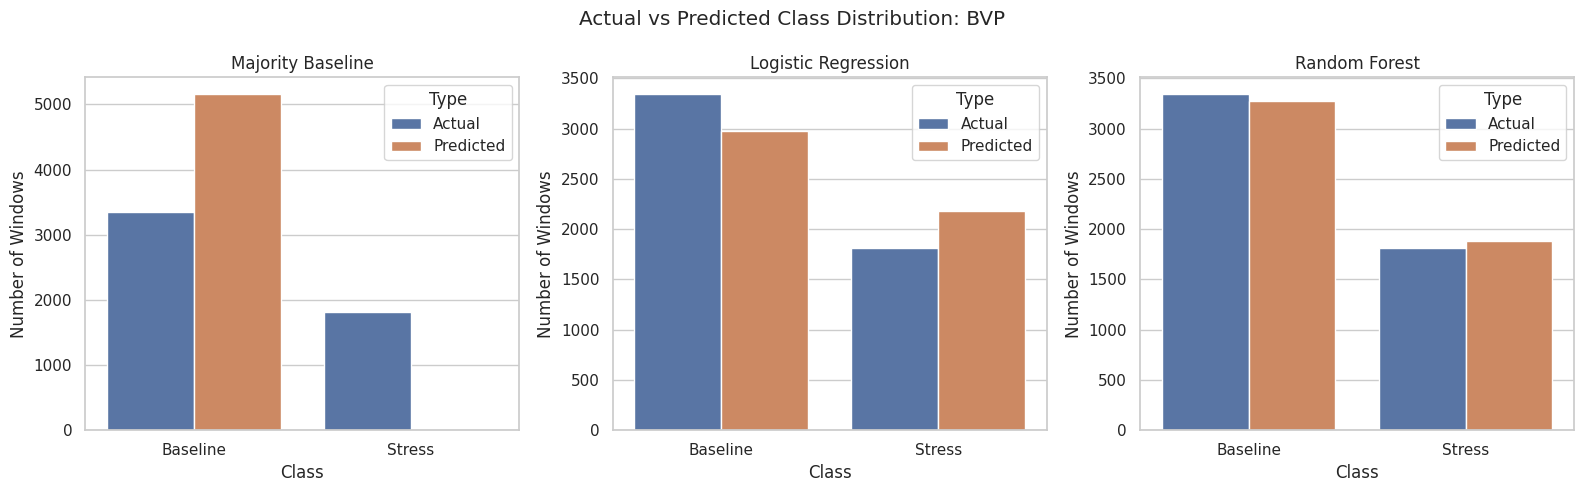

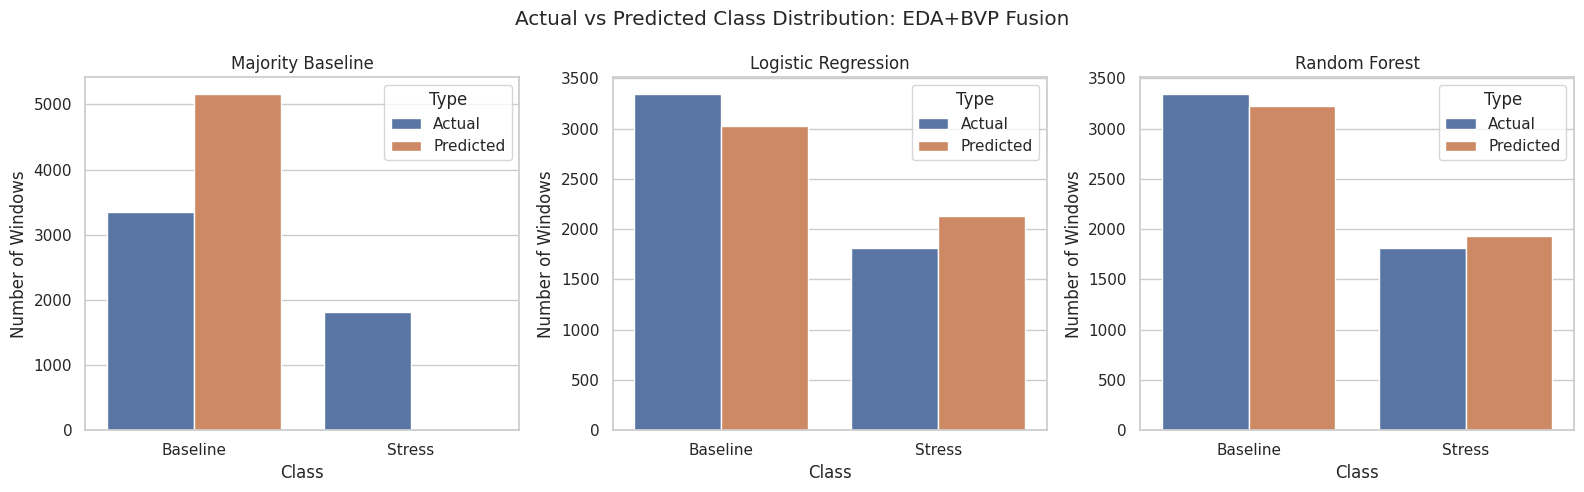


EDA - Majority Baseline
              precision    recall  f1-score   support

    Baseline       0.65      1.00      0.79      3342
      Stress       0.00      0.00      0.00      1815

    accuracy                           0.65      5157
   macro avg       0.32      0.50      0.39      5157
weighted avg       0.42      0.65      0.51      5157


EDA - Logistic Regression
              precision    recall  f1-score   support

    Baseline       0.85      0.83      0.84      3342
      Stress       0.70      0.73      0.71      1815

    accuracy                           0.79      5157
   macro avg       0.77      0.78      0.77      5157
weighted avg       0.79      0.79      0.79      5157


EDA - Random Forest
              precision    recall  f1-score   support

    Baseline       0.85      0.86      0.86      3342
      Stress       0.74      0.72      0.73      1815

    accuracy                           0.81      5157
   macro avg       0.79      0.79      0.79      5157
w

In [ ]:

# ============================================================
# WESAD STRESS DETECTION: COMPLETE PROJECT
# EDA, BVP, SENSOR FUSION, LOSO, MODELS AND VISUALIZATIONS
# ============================================================

from google.colab import drive, files
drive.mount("/content/Mydrive")

import os
import zipfile
import pickle
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from scipy.signal import butter, sosfiltfilt, find_peaks

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ============================================================
# 1. DATASET EXTRACTION
# ============================================================


# ============================================================
# 1. DATASET EXTRACTION
# ============================================================

# Google Drive mount path
DRIVE_PATH = "/content/Mydrive"

# Check the actual dataset location
print("Files in Google Drive:")
print(os.listdir(DRIVE_PATH))

# Dataset ZIP path
ZIP_PATH = os.path.join(DRIVE_PATH, "MyDrive", "WESAD.zip")

EXTRACT_PATH = "/content/WESAD"
OUTPUT_PATH = "/content/WESAD"

# Verify dataset path
if not os.path.isfile(ZIP_PATH):
    raise FileNotFoundError(
        f"WESAD.zip not found at: {ZIP_PATH}. "
        "Check the printed folder contents."
    )

os.makedirs(EXTRACT_PATH, exist_ok=True)
os.makedirs(OUTPUT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extraction completed successfully!")


# ============================================================
# 2. SETTINGS
# ============================================================

FS_EDA = 4
FS_BVP = 64
FS_LABEL = 700

WINDOW_SECONDS = 60
STRIDE_SECONDS = 5

WINDOW_SIZE = WINDOW_SECONDS * FS_EDA
STRIDE_SIZE = STRIDE_SECONDS * FS_EDA
BVP_RATIO = FS_BVP // FS_EDA

CLASS_NAMES = ["Baseline", "Stress"]

EDA_FEATURE_NAMES = [
    "EDA Mean",
    "EDA Std",
    "EDA Min",
    "EDA Max",
    "EDA Range",
    "Tonic Mean",
    "Tonic Std",
    "Tonic Slope",
    "Phasic Std",
    "Phasic Abs Mean",
    "Phasic Max",
    "Phasic Peak Rate"
]

BVP_FEATURE_NAMES = [
    "BVP Mean",
    "BVP Std",
    "BVP Min",
    "BVP Max",
    "BVP Range",
    "Heart Rate Mean",
    "Heart Rate Std",
    "IBI Mean",
    "IBI Std",
    "Pulse Amplitude Mean",
    "Pulse Amplitude Std",
    "Pulse Peak Rate"
]

FUSION_FEATURE_NAMES = EDA_FEATURE_NAMES + BVP_FEATURE_NAMES

# ============================================================
# 3. EDA FEATURE EXTRACTION
# ============================================================

def extract_eda_features(signal):

    signal = np.asarray(signal, dtype=float).reshape(-1)

    if len(signal) < 20 or not np.all(np.isfinite(signal)):
        raise ValueError("Invalid EDA window.")

    basic = [
        np.mean(signal),
        np.std(signal),
        np.min(signal),
        np.max(signal),
        np.ptp(signal)
    ]

    tonic_sos = butter(
        2,
        0.05,
        btype="lowpass",
        fs=FS_EDA,
        output="sos"
    )

    tonic = sosfiltfilt(tonic_sos, signal)
    phasic = signal - tonic

    time_axis = np.arange(len(tonic)) / FS_EDA

    tonic_slope = np.polyfit(
        time_axis,
        tonic,
        1
    )[0]

    peaks, _ = find_peaks(
        phasic,
        distance=FS_EDA,
        prominence=max(np.std(phasic) * 0.5, 1e-8)
    )

    physiological = [
        np.mean(tonic),
        np.std(tonic),
        tonic_slope,
        np.std(phasic),
        np.mean(np.abs(phasic)),
        np.max(phasic),
        len(peaks) / WINDOW_SECONDS
    ]

    return np.asarray(basic + physiological, dtype=float)


# ============================================================
# 4. BVP FEATURE EXTRACTION
# ============================================================

def extract_bvp_features(signal):

    signal = np.asarray(signal, dtype=float).reshape(-1)

    if len(signal) < 100 or not np.all(np.isfinite(signal)):
        raise ValueError("Invalid BVP window.")

    bvp_sos = butter(
        3,
        [0.5, 8.0],
        btype="bandpass",
        fs=FS_BVP,
        output="sos"
    )

    filtered = sosfiltfilt(bvp_sos, signal)

    peaks, _ = find_peaks(
        filtered,
        distance=int(0.3 * FS_BVP),
        prominence=max(np.std(filtered) * 0.3, 1e-8)
    )

    basic = [
        np.mean(filtered),
        np.std(filtered),
        np.min(filtered),
        np.max(filtered),
        np.ptp(filtered)
    ]

    hr_mean = 0.0
    hr_std = 0.0
    ibi_mean = 0.0
    ibi_std = 0.0
    amp_mean = 0.0
    amp_std = 0.0

    if len(peaks) >= 2:

        intervals = np.diff(peaks) / FS_BVP

        valid = (
            (intervals >= 60.0 / 200.0) &
            (intervals <= 60.0 / 40.0)
        )

        valid_intervals = intervals[valid]

        if len(valid_intervals) > 0:

            heart_rates = 60.0 / valid_intervals

            hr_mean = np.mean(heart_rates)
            hr_std = np.std(heart_rates)
            ibi_mean = np.mean(valid_intervals)
            ibi_std = np.std(valid_intervals)

        amplitudes = np.diff(filtered[peaks])

        if len(amplitudes) > 0:
            amp_mean = np.mean(amplitudes)
            amp_std = np.std(amplitudes)

    physiological = [
        hr_mean,
        hr_std,
        ibi_mean,
        ibi_std,
        amp_mean,
        amp_std,
        len(peaks) / WINDOW_SECONDS
    ]

    return np.asarray(basic + physiological, dtype=float)


# ============================================================
# 5. LOAD SUBJECT SIGNALS
# ============================================================

def load_subject(file_path):

    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    subject_name = os.path.basename(file_path).replace(".pkl", "")

    wrist = data["signal"]["wrist"]

    eda = np.asarray(wrist["EDA"], dtype=float).reshape(-1)
    bvp = np.asarray(wrist["BVP"], dtype=float).reshape(-1)
    labels = np.asarray(data["label"]).reshape(-1)

    label_indices = (
        np.arange(len(eda)) * FS_LABEL / FS_EDA
    ).astype(int)

    valid = label_indices < len(labels)

    eda = eda[valid]
    label_indices = label_indices[valid]

    labels_4hz = labels[label_indices]

    n = min(
        len(eda),
        len(labels_4hz),
        len(bvp) // BVP_RATIO
    )

    return (
        subject_name,
        eda[:n],
        bvp[:n * BVP_RATIO],
        labels_4hz[:n]
    )


# ============================================================
# 6. CREATE WINDOWS AND EXTRACT FEATURES
# ============================================================

def make_windows(eda, bvp, labels, subject):

    rows = []

    n = min(
        len(eda),
        len(labels),
        len(bvp) // BVP_RATIO
    )

    for start in range(
        0,
        n - WINDOW_SIZE + 1,
        STRIDE_SIZE
    ):

        end = start + WINDOW_SIZE

        eda_window = eda[start:end]

        bvp_window = bvp[
            start * BVP_RATIO:end * BVP_RATIO
        ]

        label_window = labels[start:end]

        counts = Counter(label_window.tolist())

        if counts.get(1, 0) == len(label_window):
            target = 0

        elif counts.get(2, 0) == len(label_window):
            target = 1

        else:
            continue

        try:
            eda_features = extract_eda_features(eda_window)
            bvp_features = extract_bvp_features(bvp_window)

        except (ValueError, FloatingPointError):
            continue

        if not (
            np.all(np.isfinite(eda_features)) and
            np.all(np.isfinite(bvp_features))
        ):
            continue

        rows.append({
            "Subject": subject,
            "Label": target,
            "EDA": eda_features,
            "BVP": bvp_features
        })

    return rows


# ============================================================
# 7. PROCESS SUBJECTS
# ============================================================

all_rows = []

for file_path in pkl_files:

    subject = os.path.basename(file_path).replace(".pkl", "")

    try:
        subject_num = int(subject[1:])
    except (ValueError, IndexError):
        continue

    # Process S2-S17, excluding S12
    if subject_num < 2 or subject_num > 17 or subject_num == 12:
        continue

    print("Processing:", subject)

    try:
        subject, eda, bvp, labels = load_subject(file_path)

        rows = make_windows(
            eda,
            bvp,
            labels,
            subject
        )

        all_rows.extend(rows)

        print("Valid windows:", len(rows))

    except Exception as error:
        print("Skipped:", subject, "|", str(error))


if not all_rows:
    raise ValueError(
        "No valid windows generated. Check the dataset and labels."
    )

print("\nTotal windows:", len(all_rows))
print("Subjects:", sorted(set(r["Subject"] for r in all_rows)))

# ============================================================
# 8. CREATE FEATURE MATRICES
# ============================================================

X_eda = np.asarray(
    [r["EDA"] for r in all_rows],
    dtype=float
)

X_bvp = np.asarray(
    [r["BVP"] for r in all_rows],
    dtype=float
)

X_fusion = np.concatenate(
    [X_eda, X_bvp],
    axis=1
)

y = np.asarray(
    [r["Label"] for r in all_rows],
    dtype=int
)

groups = np.asarray(
    [r["Subject"] for r in all_rows]
)

print("\nEDA matrix:", X_eda.shape)
print("BVP matrix:", X_bvp.shape)
print("Fusion matrix:", X_fusion.shape)

print("\nClass distribution:")
print(
    pd.Series(y).map({
        0: "Baseline",
        1: "Stress"
    }).value_counts()
)

# ============================================================
# 9. DEFINE MODELS
# ============================================================

models = {
    "Majority Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

experiments = {
    "EDA": (X_eda, EDA_FEATURE_NAMES),
    "BVP": (X_bvp, BVP_FEATURE_NAMES),
    "EDA+BVP Fusion": (X_fusion, FUSION_FEATURE_NAMES)
}

# ============================================================
# 10. LEAVE-ONE-SUBJECT-OUT EVALUATION
# ============================================================

logo = LeaveOneGroupOut()

results = []
prediction_rows = []
importance_rows = []

for experiment_name, (X, feature_names) in experiments.items():

    print("\n" + "=" * 60)
    print("EXPERIMENT:", experiment_name)
    print("=" * 60)

    for fold, (train_idx, test_idx) in enumerate(
        logo.split(X, y, groups),
        start=1
    ):

        X_train = X[train_idx]
        X_test = X[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        test_subject = groups[test_idx][0]

        if len(np.unique(y_train)) < 2:
            print("Skipping fold: training data has one class.")
            continue

        print(
            f"Fold {fold}: {test_subject}, "
            f"train={len(train_idx)}, test={len(test_idx)}"
        )

        for model_name, model_template in models.items():

            model = clone(model_template)

            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            results.append({
                "Experiment": experiment_name,
                "Subject": test_subject,
                "Model": model_name,
                "Accuracy": accuracy_score(
                    y_test, predictions
                ),
                "Balanced Accuracy": balanced_accuracy_score(
                    y_test, predictions
                ),
                "Macro F1": f1_score(
                    y_test,
                    predictions,
                    average="macro",
                    zero_division=0
                )
            })

            for actual, predicted in zip(y_test, predictions):

                prediction_rows.append({
                    "Experiment": experiment_name,
                    "Subject": test_subject,
                    "Model": model_name,
                    "Actual": actual,
                    "Predicted": predicted
                })

            if model_name == "Random Forest":

                for feature, importance in zip(
                    feature_names,
                    model.feature_importances_
                ):

                    importance_rows.append({
                        "Experiment": experiment_name,
                        "Subject": test_subject,
                        "Feature": feature,
                        "Importance": importance
                    })


# ============================================================
# 11. SAVE EVALUATION RESULTS
# ============================================================

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(prediction_rows)
importance_df = pd.DataFrame(importance_rows)

if results_df.empty or predictions_df.empty:
    raise ValueError("No evaluation results were generated.")

summary_df = (
    results_df.groupby(["Experiment", "Model"])[
        ["Accuracy", "Balanced Accuracy", "Macro F1"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("\nSUBJECT-WISE RESULTS")
display(
    results_df.sort_values(
        ["Experiment", "Subject", "Model"]
    ).round(4)
)

print("\nOVERALL RESULTS")
display(summary_df)

results_df.to_csv(
    "/content/WESAD_subject_results.csv",
    index=False
)

summary_df.to_csv(
    "/content/WESAD_overall_results.csv"
)

predictions_df.to_csv(
    "/content/WESAD_predictions.csv",
    index=False
)

importance_df.to_csv(
    "/content/WESAD_feature_importance.csv",
    index=False
)

# ============================================================
# 12. VISUALIZATION SETTINGS
# ============================================================

def save_graph(filename):

    plt.tight_layout()

    plt.savefig(
        os.path.join(OUTPUT_PATH, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


model_order = list(models.keys())
experiment_order = list(experiments.keys())

results_df["Experiment"] = pd.Categorical(
    results_df["Experiment"],
    categories=experiment_order,
    ordered=True
)

results_df["Model"] = pd.Categorical(
    results_df["Model"],
    categories=model_order,
    ordered=True
)

# ============================================================
# 13. GRAPH: CLASS DISTRIBUTION
# ============================================================

class_counts = pd.Series(y).map({
    0: "Baseline",
    1: "Stress"
}).value_counts().reindex(
    CLASS_NAMES,
    fill_value=0
)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette="Set2",
    legend=False
)

plt.title("WESAD Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Windows")

save_graph("01_class_distribution.png")

# ============================================================
# 14. GRAPHS: MODEL PERFORMANCE COMPARISON
# ============================================================

metrics = [
    ("Accuracy", "02_accuracy.png"),
    ("Balanced Accuracy", "03_balanced_accuracy.png"),
    ("Macro F1", "04_macro_f1.png")
]

for metric, filename in metrics:

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=results_df,
        x="Experiment",
        y=metric,
        hue="Model",
        errorbar="sd",
        capsize=0.08
    )

    plt.title(f"{metric} Comparison Across Experiments")
    plt.xlabel("Feature Set")
    plt.ylabel(metric)
    plt.ylim(0, 1.05)
    plt.xticks(rotation=10)
    plt.legend(title="Model")

    save_graph(filename)


# ============================================================
# 15. GRAPH: MEAN PERFORMANCE WITH STANDARD DEVIATION
# ============================================================

summary_plot = (
    results_df.groupby(
        ["Experiment", "Model"],
        observed=True
    )[
        ["Accuracy", "Balanced Accuracy", "Macro F1"]
    ]
    .agg(["mean", "std"])
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

for ax, metric in zip(
    axes,
    ["Accuracy", "Balanced Accuracy", "Macro F1"]
):

    means = summary_plot[(metric, "mean")].unstack()
    stds = summary_plot[(metric, "std")].unstack()

    means = means.reindex(index=experiment_order)
    means = means.reindex(columns=model_order)

    stds = stds.reindex(index=experiment_order)
    stds = stds.reindex(columns=model_order)

    x = np.arange(len(experiment_order))
    width = 0.25

    for i, model_name in enumerate(model_order):

        offset = (i - 1) * width

        ax.bar(
            x + offset,
            means[model_name].to_numpy(),
            width,
            yerr=stds[model_name].fillna(0).to_numpy(),
            capsize=3,
            label=model_name
        )

    ax.set_title(metric)
    ax.set_xticks(x)
    ax.set_xticklabels(experiment_order, rotation=20)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel("Score")

axes[0].legend(fontsize=8)

plt.suptitle("LOSO Performance: Mean and Standard Deviation")

save_graph("05_mean_std_comparison.png")


# ============================================================
# 16. GRAPH: SUBJECT-WISE ACCURACY HEATMAPS
# ============================================================

for experiment_name in experiment_order:

    subset = results_df[
        results_df["Experiment"] == experiment_name
    ].copy()

    heatmap_data = subset.pivot(
        index="Subject",
        columns="Model",
        values="Accuracy"
    ).reindex(columns=model_order)

    heatmap_data = heatmap_data.reindex(
        sorted(
            heatmap_data.index,
            key=lambda s: int(str(s)[1:])
        )
    )

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        vmin=0,
        vmax=1
    )

    plt.title(f"Subject-wise Accuracy: {experiment_name}")
    plt.xlabel("Model")
    plt.ylabel("Held-Out Subject")

    save_graph(
        "06_heatmap_" +
        experiment_name.lower().replace("+", "_").replace(" ", "_") +
        ".png"
    )


# ============================================================
# 17. GRAPH: SUBJECT-WISE ACCURACY LINE PLOTS
# ============================================================

for experiment_name in experiment_order:

    subset = results_df[
        results_df["Experiment"] == experiment_name
    ]

    plt.figure(figsize=(12, 6))

    for model_name in model_order:

        temp = subset[
            subset["Model"] == model_name
        ].copy()

        temp["Subject_Number"] = temp["Subject"].apply(
            lambda s: int(str(s)[1:])
        )

        temp = temp.sort_values("Subject_Number")

        plt.plot(
            temp["Subject"],
            temp["Accuracy"],
            marker="o",
            label=model_name
        )

    plt.title(f"Accuracy Across Subjects: {experiment_name}")
    plt.xlabel("Held-Out Subject")
    plt.ylabel("Accuracy")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=45)
    plt.legend()

    save_graph(
        "07_subject_line_" +
        experiment_name.lower().replace("+", "_").replace(" ", "_") +
        ".png"
    )


# ============================================================
# 18. GRAPHS: CONFUSION MATRICES
# ============================================================

for experiment_name in experiment_order:

    for model_name in model_order:

        temp = predictions_df[
            (predictions_df["Experiment"] == experiment_name) &
            (predictions_df["Model"] == model_name)
        ]

        cm = confusion_matrix(
            temp["Actual"],
            temp["Predicted"],
            labels=[0, 1]
        )

        plt.figure(figsize=(6, 5))

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES
        )

        plt.title(
            f"Confusion Matrix\n{experiment_name} - {model_name}"
        )

        plt.xlabel("Predicted Class")
        plt.ylabel("Actual Class")

        filename = (
            "08_cm_" +
            experiment_name.lower().replace("+", "_").replace(" ", "_") +
            "_" +
            model_name.lower().replace(" ", "_") +
            ".png"
        )

        save_graph(filename)


# ============================================================
# 19. GRAPH: RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

for experiment_name in experiment_order:

    temp = importance_df[
        importance_df["Experiment"] == experiment_name
    ]

    if temp.empty:
        continue

    feature_ranking = (
        temp.groupby("Feature")["Importance"]
        .mean()
        .sort_values(ascending=False)
        .head(15)
        .reset_index()
    )

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=feature_ranking,
        x="Importance",
        y="Feature",
        color="steelblue"
    )

    plt.title(
        f"Random Forest Feature Importance: {experiment_name}"
    )

    plt.xlabel("Mean Importance Across Held-Out Subjects")
    plt.ylabel("Feature")

    save_graph(
        "09_feature_importance_" +
        experiment_name.lower().replace("+", "_").replace(" ", "_") +
        ".png"
    )


# ============================================================
# 20. GRAPH: EDA FEATURE CORRELATION HEATMAP
# ============================================================

eda_df = pd.DataFrame(
    X_eda,
    columns=EDA_FEATURE_NAMES
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    eda_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("EDA Feature Correlation Heatmap")

save_graph("10_eda_correlation_heatmap.png")


# ============================================================
# 21. GRAPH: BVP FEATURE CORRELATION HEATMAP
# ============================================================

bvp_df = pd.DataFrame(
    X_bvp,
    columns=BVP_FEATURE_NAMES
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    bvp_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("BVP Feature Correlation Heatmap")

save_graph("11_bvp_correlation_heatmap.png")


# ============================================================
# 22. GRAPH: ACCURACY DISTRIBUTION BOXPLOTS
# ============================================================

for experiment_name in experiment_order:

    subset = results_df[
        results_df["Experiment"] == experiment_name
    ]

    plt.figure(figsize=(9, 6))

    sns.boxplot(
        data=subset,
        x="Model",
        y="Accuracy",
        hue="Model",
        order=model_order,
        hue_order=model_order,
        palette="Set2",
        legend=False
    )

    plt.title(
        f"Accuracy Distribution Across Subjects: {experiment_name}"
    )

    plt.xlabel("Model")
    plt.ylabel("Accuracy")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=15)

    save_graph(
        "12_boxplot_" +
        experiment_name.lower().replace("+", "_").replace(" ", "_") +
        ".png"
    )


# ============================================================
# 23. GRAPHS: EDA FEATURE DISTRIBUTIONS
# ============================================================

selected_features = [
    "EDA Mean",
    "EDA Std",
    "Tonic Mean",
    "Phasic Std"
]

eda_labels = pd.Series(y).map({
    0: "Baseline",
    1: "Stress"
})

for feature in selected_features:

    feature_index = EDA_FEATURE_NAMES.index(feature)

    plot_df = pd.DataFrame({
        "Feature Value": X_eda[:, feature_index],
        "Class": eda_labels
    })

    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=plot_df,
        x="Feature Value",
        hue="Class",
        bins=30,
        element="step",
        stat="density",
        common_norm=False
    )

    plt.title(f"{feature} Distribution by Class")
    plt.xlabel(feature)
    plt.ylabel("Density")

    save_graph(
        "13_distribution_" +
        feature.lower().replace(" ", "_") +
        ".png"
    )


# ============================================================
# 24. GRAPHS: BVP FEATURE DISTRIBUTIONS
# ============================================================

selected_bvp_features = [
    "Heart Rate Mean",
    "Heart Rate Std",
    "IBI Mean",
    "Pulse Amplitude Mean"
]

for feature in selected_bvp_features:

    feature_index = BVP_FEATURE_NAMES.index(feature)

    plot_df = pd.DataFrame({
        "Feature Value": X_bvp[:, feature_index],
        "Class": eda_labels
    })

    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=plot_df,
        x="Feature Value",
        hue="Class",
        bins=30,
        element="step",
        stat="density",
        common_norm=False
    )

    plt.title(f"{feature} Distribution by Class")
    plt.xlabel(feature)
    plt.ylabel("Density")

    save_graph(
        "14_distribution_" +
        feature.lower().replace(" ", "_") +
        ".png"
    )


# ============================================================
# 25. GRAPH: ACTUAL VS PREDICTED CLASS DISTRIBUTION
# ============================================================

class_comparison = []

for experiment_name in experiment_order:

    for model_name in model_order:

        temp = predictions_df[
            (predictions_df["Experiment"] == experiment_name) &
            (predictions_df["Model"] == model_name)
        ]

        for class_id, class_name in enumerate(CLASS_NAMES):

            class_comparison.append({
                "Experiment": experiment_name,
                "Model": model_name,
                "Class": class_name,
                "Type": "Actual",
                "Count": int(
                    (temp["Actual"] == class_id).sum()
                )
            })

            class_comparison.append({
                "Experiment": experiment_name,
                "Model": model_name,
                "Class": class_name,
                "Type": "Predicted",
                "Count": int(
                    (temp["Predicted"] == class_id).sum()
                )
            })

comparison_df = pd.DataFrame(class_comparison)

for experiment_name in experiment_order:

    subset = comparison_df[
        comparison_df["Experiment"] == experiment_name
    ]

    fig, axes = plt.subplots(
        1, 3,
        figsize=(16, 5)
    )

    for ax, model_name in zip(axes, model_order):

        temp = subset[
            subset["Model"] == model_name
        ]

        sns.barplot(
            data=temp,
            x="Class",
            y="Count",
            hue="Type",
            ax=ax
        )

        ax.set_title(model_name)
        ax.set_xlabel("Class")
        ax.set_ylabel("Number of Windows")

    plt.suptitle(
        f"Actual vs Predicted Class Distribution: {experiment_name}"
    )

    save_graph(
        "15_actual_predicted_" +
        experiment_name.lower().replace("+", "_").replace(" ", "_") +
        ".png"
    )


# ============================================================
# 26. CLASSIFICATION REPORTS
# ============================================================

for experiment_name in experiment_order:

    for model_name in model_order:

        temp = predictions_df[
            (predictions_df["Experiment"] == experiment_name) &
            (predictions_df["Model"] == model_name)
        ]

        print("\n" + "=" * 60)
        print(experiment_name, "-", model_name)
        print("=" * 60)

        print(
            classification_report(
                temp["Actual"],
                temp["Predicted"],
                labels=[0, 1],
                target_names=CLASS_NAMES,
                zero_division=0
            )
        )


# ============================================================
# 27. SAVE ALL OUTPUT FILES
# ============================================================

results_df.to_csv(
    "/content/WESAD_subject_results.csv",
    index=False
)

summary_df.to_csv(
    "/content/WESAD_overall_results.csv"
)

predictions_df.to_csv(
    "/content/WESAD_predictions.csv",
    index=False
)

importance_df.to_csv(
    "/content/WESAD_feature_importance.csv",
    index=False
)

# Include result tables in the graph/output ZIP
shutil.copy(
    "/content/WESAD_subject_results.csv",
    OUTPUT_PATH
)

shutil.copy(
    "/content/WESAD_overall_results.csv",
    OUTPUT_PATH
)

shutil.copy(
    "/content/WESAD_predictions.csv",
    OUTPUT_PATH
)

shutil.copy(
    "/content/WESAD_feature_importance.csv",
    OUTPUT_PATH
)

zip_path = shutil.make_archive(
    "/content/WESAD_visualizations",
    "zip",
    OUTPUT_PATH
)

print("\n" + "=" * 60)
print("PROJECT COMPLETED")
print("=" * 60)

print("Subject results: /content/WESAD_subject_results.csv")
print("Overall results: /content/WESAD_overall_results.csv")
print("Predictions: /content/WESAD_predictions.csv")
print("Feature importance: /content/WESAD_feature_importance.csv")
print("Graphs folder:", OUTPUT_PATH)
print("All outputs ZIP:", zip_path)

files.download(zip_path)


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=summary_df)